<a href="https://colab.research.google.com/github/superextraordinaryaccount/Lab3/blob/master/Numerical_Methods_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторная работа №1
## Численные методы алгебры

**Цель:** реализовать прямые и итерационные методы решения СЛАУ, методы решения нелинейных уравнений и систем; исследовать точность, обусловленность и сходимость.


### Правила выполнения
- Сделайте собственную копию блокнота. Заполняйте ячейки с `TODO`, добавляйте эксперименты и выводы непосредственно в него.
- XML-модели, визуализация и регулятор предоставлены готовыми. Их переписывать не требуется.
- В собственных решателях запрещены `np.linalg.solve`, `inv`, `lu`, `cholesky` и аналогичные готовые решатели/разложения. Они разрешены только для эталонных проверок. `norm`, матричные операции и вычисление числа обусловленности разрешены.
- Использование агентов разрешено. На защите необходимо объяснить код, предсказать результат изменения параметров и провести эксперимент.
- Задания обозначены **А1–А5, Б1–Б3**.

## Подготовка
При первой установке выполните следующую ячейку. Затем перезапустите сеанс через меню «Среда выполнения → Перезапустить сеанс» и продолжите с импортов. Если MuJoCo уже импортировался с другим OpenGL-бэкендом, перезапуск обязателен. GPU не требуется.


In [ ]:
!apt-get -qq update
!apt-get -qq install -y libosmesa6
%pip -q install mujoco==3.3.7 mediapy


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package libosmesa6:amd64.
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libosmesa6_25.1.7-1ubuntu2~24.04.2_amd64.deb ...
Unpacking libosmesa6:amd64 (25.1.7-1ubuntu2~24.04.2) ...
Setting up libosmesa6:amd64 (25.1.7-1ubuntu2~24.04.2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libumf.so.1 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_loader.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapter_opencl.so.0 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libtbbbind_2_5.so.3 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libur_adapte

In [ ]:
import os

# Обязательно до импорта mujoco или OpenGL.
os.environ["MUJOCO_GL"] = "osmesa"
os.environ["PYOPENGL_PLATFORM"] = "osmesa"

import ctypes
import ctypes.util

library_path = ctypes.util.find_library("OSMesa")
print("Библиотека OSMesa:", library_path)

if library_path is None:
    raise RuntimeError("OSMesa не найдена. Повтори установку libosmesa6.")

ctypes.CDLL(library_path)

import numpy as np
import matplotlib.pyplot as plt
import mujoco
import mediapy as media
from time import perf_counter

print("MuJoCo:", mujoco.__version__)


Библиотека OSMesa: libOSMesa.so.8
MuJoCo: 3.3.7


# А. СЛАУ и равновесие упругой решётки
## А1. Реализация прямых методов
Реализуйте метод Гаусса с частичным выбором главного элемента, [LU с перестановками строк](https://ru.wikipedia.org/wiki/LUP-разложение) ($PA=LU$), метод Холецкого и треугольные решатели.

Функции не должны изменять исходные массивы. Предусмотрите диагностику вырожденных систем и неположительно определённых матриц.

`lu_factor` возвращает `(P, L, U)`; `cholesky_factor` — нижнетреугольную матрицу `L`.


In [ ]:
def _is_singular(value, scale, n):
    """Ноль ли это по сравнению с масштабом матрицы."""
    return abs(value) <= n * np.finfo(float).eps * scale



def forward_substitution(L, b):
    # TODO А1: решить нижнетреугольную систему.
    """
    Прямой ход: решает систему Lx = b, где L - нижнетреугольная матрица
    """
    n = L.shape[0] #кол-во строк
    x = np.zeros(n)

    scale = np.abs(L).max()
    if any(_is_singular(d, scale, n) for d in np.diag(L)):
        raise np.linalg.LinAlgError("Матрица вырождена:0 на диагонали L")

    for i in range(n):
        # Векторизованный подсчет суммы
        s = np.dot(L[i, :i], x[:i])
        x[i] = (b[i] - s) / L[i, i]
    return x



def backward_substitution(U, b):
    # TODO А1: решить верхнетреугольную систему.

    """
    Обратный ход: решает систему Ux = b, где U - верхнетреугольная матрица
    """
    n = U.shape[0]
    x = np.zeros(n)

    scale = np.abs(U).max()
    if any(_is_singular(d, scale, n) for d in np.diag(U)):
        raise np.linalg.LinAlgError("Матрица вырождена:0 на диагонали U")
    for i in range(n - 1, -1, -1):
        s = np.dot(U[i, i+1:], x[i+1:])
        x[i] = (b[i] - s) / U[i, i]
    return x



def gauss(A, b):
    # TODO А1: Гаусс с частичным выбором главного элемента.
    A = A.copy().astype(float)  #float, чтобы избежать целочисленного деления
    b = b.copy().astype(float)
    n = A.shape[0]
    scale = np.abs(A).max()

    for i in range(n):
      # Поиск главного элемента
      pivot_row = i + np.argmax(np.abs(A[i:, i]))

      if _is_singular(A[pivot_row, i], scale, n):
        raise np.linalg.LinAlgError("Матрица вырождена")

      #Перестановка строк
      if pivot_row != i:
            A[[i, pivot_row]] = A[[pivot_row, i]]
            b[[i, pivot_row]] = b[[pivot_row, i]]

      #обнуление элементов под диагональю
      for j in range(i + 1, n):
            factor = A[j, i] / A[i, i]
            A[j, i:] -= factor * A[i, i:]
            b[j] -= factor * b[i]

    return backward_substitution(A, b)

def lu_factor(A):
    # TODO А1: PA = LU. Учитывать перестановки в уже заполненной части L.

    """LU-разложение с перестановками строк: PA = LU.
    Возвращает кортеж (P, L, U)."""
    A = A.copy().astype(float)
    n = A.shape[0]

    # Инициализация
    P = np.eye(n) # Матрица перестановок(из 1)
    L = np.eye(n) # Нижнетреугольная (1 стоят  на диагонали)
    U = A.copy()  # Верхнетреугольная(Получаем Гауссом из A)
    scale = np.abs(U).max()

    for i in range(n):
        # Поиск главного элемента
        pivot_row = i + np.argmax(np.abs(U[i:, i]))

        if _is_singular(U[pivot_row, i], scale, n):
            raise np.linalg.LinAlgError("Матрица вырождена")

        #перестановка
        if pivot_row != i:
            U[[i, pivot_row]] = U[[pivot_row, i]]
            P[[i, pivot_row]] = P[[pivot_row, i]]
            # Меняем местами уже вычисленные элементы в L (только левую часть до i)
            L[[i, pivot_row], :i] = L[[pivot_row, i], :i]

        # Вычисление множителей и обновление U
        for j in range(i + 1, n):
            multiplier = U[j, i] / U[i, i]
            L[j, i] = multiplier
            U[j, i:] -= multiplier * U[i, i:]

    return P, L, U


def lu_solve(factors, b):
    P, L, U = factors
    return backward_substitution(U, forward_substitution(L, P @ b))


def cholesky_factor(A):
    # TODO А1: проверить симметрию и реализовать A = L @ L.T.
    """
    Разложение Холецкого: A = L @ L^T
    Требует симметричности и положительной определенности.
    """
    n = A.shape[0]
    L = np.zeros((n, n))

    if not np.allclose(A, A.T):
        raise ValueError("Матрица не симметрична")

    for i in range(n):
        for j in range(i + 1):
            s = np.dot(L[i, :j], L[j, :j])

            if i == j:
                # Диагональные элементы
                val = A[i, i] - s
                if val <= 0:
                    raise ValueError("Матрица не является положительно определенной")
                L[i, j] = np.sqrt(val)
            else:
                # Внедиагональные элементы
                L[i, j] = (A[i, j] - s) / L[j, j]

    return L


def cholesky_solve(A, b):
    L = cholesky_factor(A)
    return backward_substitution(L.T, forward_substitution(L, b))


### Контрольные проверки А1
Ячейка проверяет решение, восстановление разложений и сохранение исходных данных. Добавьте собственные проверки вырожденной системы и отказа Холецкого для неподходящей матрицы. Прохождение этих проверок не заменяет эксперименты.


In [ ]:
rng = np.random.default_rng(42)
for size in (10, 50):
    B = rng.normal(size=(size, size))
    A = B + (size + 1)*np.eye(size)
    x_exact = rng.normal(size=size)
    b = A @ x_exact
    A_before, b_before = A.copy(), b.copy()
    P, L, U = lu_factor(A)
    np.testing.assert_allclose(P @ A, L @ U, atol=1e-9)
    for x in (gauss(A, b), lu_solve((P, L, U), b)):
        np.testing.assert_allclose(x, x_exact, rtol=1e-8, atol=1e-9)
    np.testing.assert_array_equal(A, A_before)
    np.testing.assert_array_equal(b, b_before)
    S = B.T @ B + np.eye(size)
    C = cholesky_factor(S)
    np.testing.assert_allclose(C @ C.T, S, atol=1e-9)
    np.testing.assert_allclose(cholesky_solve(S, S @ x_exact), x_exact,
                               rtol=1e-8, atol=1e-9)
A_pivot = np.array([[0., 2.], [1., 3.]])
b_pivot = A_pivot @ np.array([1., -2.])
np.testing.assert_allclose(gauss(A_pivot, b_pivot), [1., -2.])
np.testing.assert_allclose(lu_solve(lu_factor(A_pivot), b_pivot), [1., -2.])
print("Базовые проверки А1 пройдены.")


Базовые проверки А1 пройдены.


In [ ]:
#TODO: Дополнительные провекрки, блок, чтобы показать что они работают

# Проверка на вырожденную систему (для Гаусса и LU)
A_singular = np.array([[1., 2.], [2., 4.]]) # Вторая строка = 2 * первая
b_singular = np.array([1., 2.])

try:
    gauss(A_singular, b_singular)
    print("Ошибка: Гаусс не заметил вырожденность")
except np.linalg.LinAlgError:
    print("Успех: Гаусс выбросил исключение для вырожденной матрицы")

try:
    lu_factor(A_singular)
    print("Ошибка: LU разложение не заметило вырожденность")
except np.linalg.LinAlgError:
    print("Успех: LU разложение выбросило исключение для вырожденной матрицы")

#Проверка отказа Холецкого
# Матрица не симметрична
A_not_sym = np.array([[4., 12.], [3., -16.]])
try:
    cholesky_factor(A_not_sym)
    print("Ошибка: Функция разложения Холецкого приняла несимметричную матрицу")
except ValueError as e:
    print(f"Успех: функция разложения Холецкого поймала ошибку (несимметричность)")

# Матрица симметрична, но не положительно определена
A_not_pd = np.array([[1., 2.], [2., 1.]]) # Собственные числа 3 и -1
try:
    cholesky_factor(A_not_pd)
    print("Ошибка: функция Холецкого приняла неположительно определенную матрицу")
except ValueError as e:
    print(f"Успех: функция Холецкого поймала ошибку (не полож. определенность)")


Успех: Гаусс выбросил исключение для вырожденной матрицы
Успех: LU разложение выбросило исключение для вырожденной матрицы
Успех: функция разложения Холецкого поймала ошибку (несимметричность)
Успех: функция Холецкого поймала ошибку (не полож. определенность)


## 1. Упругая решётка: математическая модель

Рассмотрим решётку площадок, каждая из которых может перемещаться только вертикально. Соседние площадки соединены упругими связями. Каждая площадка также имеет пружинную опору относительно неподвижного основания.

Положительное перемещение $u_i$ направлено вниз.

Обозначения:
- $k_0$ — жёсткость опоры;
- $k_c$ — жёсткость связи соседей;
- $f_i$ — внешняя сила, направленная вниз;
- $N(i)$ — множество соседей площадки $i$.

Условие равновесия площадки:

$$
k_0u_i+\sum_{j\in N(i)}k_c(u_i-u_j)=f_i.
$$

Система уравнений всех площадок записывается в виде

$$
Ku=f.
$$

Элементы матрицы:

$$
K_{ii}=k_0+|N(i)|k_c,
$$

$$
K_{ij}=-k_c
$$

для соседних площадок; остальные внедиагональные элементы равны нулю.

При $k_0>0$ и $k_c>0$ матрица симметрична и положительно определена:

$$
u^\top Ku
=
k_0\sum_i u_i^2+
k_c\sum_{(i,j)\in E}(u_i-u_j)^2>0
$$

для любого ненулевого $u$. Каждая связь в множестве $E$ учитывается один раз.

При $k_0=0$ одинаковое перемещение всех площадок не деформирует связи. Матрица становится вырожденной.

Количество неизвестных: 25
Число обусловленности: 20.296181273332795
Минимальное собственное значение: 15.000000000000007


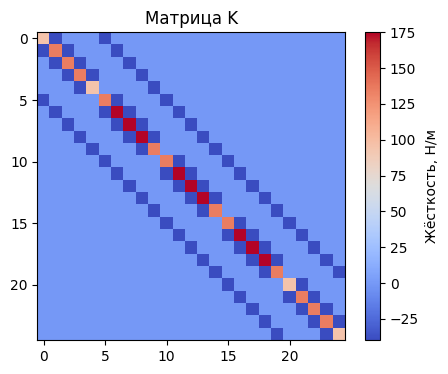

In [ ]:
SIDE = 5                  # SIDE × SIDE площадок
SPACING = 0.22            # расстояние между центрами, м
HEIGHT = 0.65             # исходная высота, м
MASS = 0.15               # масса каждой площадки, кг

K_SUPPORT = 15.0          # жёсткость опоры каждого узла, Н/м
K_COUPLING = 40.0         # жёсткость связи соседей, Н/м
DAMPING = 0.6             # демпфирование каждого сустава, Н·с/м

n = SIDE**2

def index(row, col):
    return row * SIDE + col

xy = np.array([
    [(col - (SIDE - 1)/2) * SPACING,
     (row - (SIDE - 1)/2) * SPACING]
    for row in range(SIDE)
    for col in range(SIDE)
])

# Каждую связь включаем один раз.
edges = []
for row in range(SIDE):
    for col in range(SIDE):
        i = index(row, col)
        if col + 1 < SIDE:
            edges.append((i, index(row, col + 1)))
        if row + 1 < SIDE:
            edges.append((i, index(row + 1, col)))

# Опоры дают диагональную часть.
K = K_SUPPORT * np.eye(n)

# Связь i–j даёт энергию kc/2 * (ui - uj)^2.
for i, j in edges:
    K[i, i] += K_COUPLING
    K[j, j] += K_COUPLING
    K[i, j] -= K_COUPLING
    K[j, i] -= K_COUPLING

# Постоянная сила вниз на центральной площадке.
f = np.zeros(n)
loaded_node = index(SIDE // 2, SIDE // 2)
f[loaded_node] = 8.0

print("Количество неизвестных:", n)
print("Число обусловленности:", np.linalg.cond(K))
print("Минимальное собственное значение:", np.linalg.eigvalsh(K)[0])

plt.figure(figsize=(5, 4))
plt.imshow(K, cmap="coolwarm")
plt.colorbar(label="Жёсткость, Н/м")
plt.title("Матрица K")
plt.show()


## А2. Итерационные методы
Реализуйте Якоби и Гаусса–Зейделя. В Якоби все компоненты следующего приближения вычисляются по прежнему вектору; в Зейделе используются уже обновлённые компоненты.

Критерий останова:
$$\|Ax^{(k)}-b\|_2\leq \text{atol}+\text{rtol}\|b\|_2.$$

Функция возвращает решение и массив норм невязок, включая начальную. Число шагов равно `len(residuals)-1`. При исчерпании лимита или нечисловых значениях сообщайте об ошибке. `x0=None` означает нулевой старт.


In [ ]:
def iterative_solve(A, b, method="jacobi", x0=None,
                    rtol=1e-9, atol=1e-12, max_iter=20000, history=None):
    if method not in ("jacobi", "seidel"):
        raise ValueError(f"Неизвестный метод: {method}")
    A = np.asarray(A, dtype=float); b = np.asarray(b, dtype=float)
    n = len(b)
    d = np.diag(A)
    if np.any(d == 0):
        raise np.linalg.LinAlgError("Ноль на диагонали: метод неприменим")
    x = np.zeros(n) if x0 is None else np.array(x0, dtype=float)
    stop = atol + rtol * np.linalg.norm(b)
    residuals = [np.linalg.norm(A @ x - b)]
    if history is not None: history.append(x.copy())
    for k in range(1, max_iter + 1):
        if method == "jacobi":
            x = (b - A @ x + d * x) / d
        else:
            for i in range(n):
                x[i] = (b[i] - A[i, :i] @ x[:i] - A[i, i+1:] @ x[i+1:]) / d[i]
        r = np.linalg.norm(A @ x - b)
        residuals.append(r)
        if history is not None: history.append(x.copy())
        if not np.isfinite(r):
            raise FloatingPointError(f"{method}: расходимость (inf/nan) на шаге {k}")
        if r <= stop:
            return x, np.array(residuals)
    raise RuntimeError(f"{method}: не сошелся за {max_iter} итераций, невязка {r:.2e}")

### Сравнение на одной нагрузке
Ниже используется библиотечное эталонное решение. Время одного короткого запуска не позволяет сделать надёжный вывод о скорости: для экспериментов используйте повторы и медиану времени.


Гаусс     : невязка = 2.90e-15, время = 3.95 мс
LU        : невязка = 3.28e-15, время = 2.93 мс
Холецкий  : невязка = 2.05e-15, время = 1.27 мс
Гаусс     : относительное расхождение = 2.68e-16
LU        : относительное расхождение = 2.92e-16
Холецкий  : относительное расхождение = 5.14e-16
Якоби     : относительное расхождение = 2.74e-09
Зейдель   : относительное расхождение = 3.38e-09


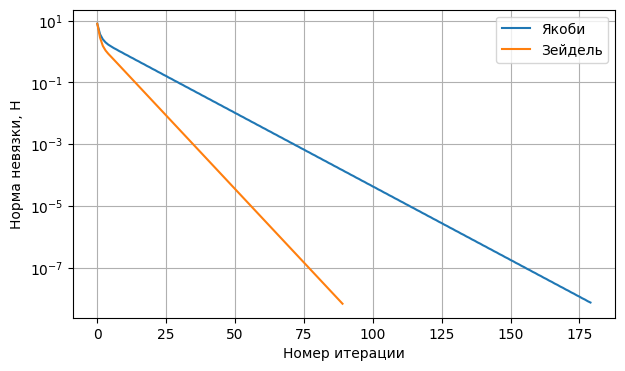

Итераций Якоби: 179
Итераций Зейделя: 89
Максимальный прогиб: 73.9 мм


In [ ]:
u_reference = np.linalg.solve(K, f)

results = {}

for name, solver in [
    ("Гаусс", gauss),
    ("LU", lambda A, b: lu_solve(lu_factor(A), b)),
    ("Холецкий", cholesky_solve),
 ]:
    start = perf_counter()
    u = solver(K, f)
    elapsed = perf_counter() - start
    results[name] = u
    print(
        f"{name:10s}: "
        f"невязка = {np.linalg.norm(K @ u - f):.2e}, "
        f"время = {elapsed*1000:.2f} мс"
    )

u_jacobi, r_jacobi = iterative_solve(K, f, "jacobi")
u_seidel, r_seidel = iterative_solve(K, f, "seidel")

results["Якоби"] = u_jacobi
results["Зейдель"] = u_seidel

for name, u in results.items():
    relative_error = (
        np.linalg.norm(u - u_reference)
        / np.linalg.norm(u_reference)
    )
    print(f"{name:10s}: относительное расхождение = {relative_error:.2e}")

plt.figure(figsize=(7, 4))
plt.semilogy(r_jacobi, label="Якоби")
plt.semilogy(r_seidel, label="Зейдель")
plt.xlabel("Номер итерации")
plt.ylabel("Норма невязки, Н")
plt.grid()
plt.legend()
plt.show()

print("Итераций Якоби:", len(r_jacobi) - 1)
print("Итераций Зейделя:", len(r_seidel) - 1)
print(f"Максимальный прогиб: {u_reference.max()*1000:.1f} мм")

#Это решение будет показано в MuJoCo красными метками.
u_static = results["Гаусс"].copy()


## А3. Проверка физической симуляцией
В MuJoCo каждая площадка имеет вертикальный сустав; `fixed tendon` задаёт пружину с координатой $u_i-u_j$. Гравитация и контакты отключены, силы задаются явно.

Динамика происходящего описывается уравнением: $M\ddot u+C\dot u+Ku=f$, где матрица $M$ скрывает инерционные свойства системы, а $C$ - скоростые взаимодействия. Так как мы рассматриваем систему в установившемся состоянии, получаем $Ku=f$.

Красные метки показывают вычисленное статическое положение; цветные площадки — физическое движение. Линии между площадками лишь визуализируют связи.

In [ ]:
body_parts = []

for i, (x, y) in enumerate(xy):
    color = "1 0.65 0.15 1" if f[i] != 0 else "0.15 0.55 0.85 1"

    body_parts.append(f"""
    <body name="node_{i}" pos="{x} {y} {HEIGHT}">
      <joint name="joint_{i}" type="slide"
             axis="0 0 -1"
             stiffness="{K_SUPPORT}"
             springref="0"
             damping="{DAMPING}"/>
      <geom name="plate_{i}" type="box"
            size="{SPACING*0.42} {SPACING*0.42} 0.025"
            mass="{MASS}" rgba="{color}"/>
    </body>
    """)

tendon_parts = []

for i, j in edges:
    tendon_parts.append(f"""
    <fixed name="spring_{i}_{j}"
           stiffness="{K_COUPLING}" springlength="0">
      <joint joint="joint_{i}" coef="1"/>
      <joint joint="joint_{j}" coef="-1"/>
    </fixed>
    """)

grid_xml = f"""
<mujoco model="elastic_grid">
  <option timestep="0.002"
          gravity="0 0 0"
          integrator="implicitfast"/>

  <visual>
    <global offwidth="640" offheight="480"/>
    <headlight ambient="0.45 0.45 0.45"/>
  </visual>

  <default>
    <geom contype="0" conaffinity="0"/>
  </default>

  <worldbody>
    <light pos="0 -1 3" dir="0 0 -1"/>
    <geom type="plane" size="3 3 0.1"
          rgba="0.92 0.94 0.97 1"/>
    {''.join(body_parts)}
  </worldbody>

  <tendon>
    {''.join(tendon_parts)}
  </tendon>
</mujoco>
"""

grid_model = mujoco.MjModel.from_xml_string(grid_xml)
grid_data = mujoco.MjData(grid_model)

body_ids = [
    mujoco.mj_name2id(grid_model, mujoco.mjtObj.mjOBJ_BODY, f"node_{i}")
    for i in range(n)
]

# Проверяем соответствие сил MuJoCo матрице K.
probe = mujoco.MjData(grid_model)
probe.qpos[:] = np.random.default_rng(42).normal(0, 0.01, n)
mujoco.mj_forward(grid_model, probe)

np.testing.assert_allclose(
    probe.qfrc_passive,
    -K @ probe.qpos,
    atol=1e-10,
)

print("Пружинные силы MuJoCo соответствуют матрице K.")


Пружинные силы MuJoCo соответствуют матрице K.


In [ ]:
GRID_FPS = 30
GRID_DURATION = 6.0
frame_times = np.arange(int(GRID_FPS * GRID_DURATION)) / GRID_FPS

camera = mujoco.MjvCamera()
camera.type = mujoco.mjtCamera.mjCAMERA_FREE
camera.lookat[:] = [0, 0, HEIGHT - 0.1]
camera.distance = max(2.3, SIDE * SPACING * 2.2)
camera.azimuth = 135
camera.elevation = -30


def add_sphere(scene, position, radius, rgba):
    if scene.ngeom >= scene.maxgeom:
        return

    mujoco.mjv_initGeom(
        scene.geoms[scene.ngeom],
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([radius, radius, radius]),
        np.asarray(position, dtype=float),
        np.eye(3).ravel(),
        np.asarray(rgba, dtype=np.float32),
    )
    scene.ngeom += 1


def add_segment(scene, start, end):
    if scene.ngeom >= scene.maxgeom:
        return

    geom = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        geom,
        mujoco.mjtGeom.mjGEOM_CAPSULE,
        np.zeros(3),
        np.zeros(3),
        np.eye(3).ravel(),
        np.array([0.3, 0.3, 0.35, 1], dtype=np.float32),
    )
    mujoco.mjv_connector(
        geom,
        mujoco.mjtGeom.mjGEOM_CAPSULE,
        0.007,
        np.asarray(start, dtype=float),
        np.asarray(end, dtype=float),
    )
    scene.ngeom += 1


mujoco.mj_resetData(grid_model, grid_data)
mujoco.mj_forward(grid_model, grid_data)

grid_frames = []
time_log = []
error_log = []
residual_log = []
velocity_log = []

grid_renderer = mujoco.Renderer(
    grid_model, height=480, width=640,
    max_geom=max(1000, 5*n)
)

try:
    for frame_time in frame_times:
        while grid_data.time < frame_time - 1e-10:
            # Сила положительна по направлению slide-сустава:
            # в нашей модели это вниз.
            grid_data.qfrc_applied[:] = f
            mujoco.mj_step(grid_model, grid_data)

        grid_data.qfrc_applied[:] = f
        mujoco.mj_forward(grid_model, grid_data)

        time_log.append(grid_data.time)
        error_log.append(np.linalg.norm(grid_data.qpos - u_static))
        residual_log.append(np.linalg.norm(K @ grid_data.qpos - f))
        velocity_log.append(np.linalg.norm(grid_data.qvel))

        grid_renderer.update_scene(grid_data, camera=camera)
        scene = grid_renderer.scene

        # Связи соседей на верхней поверхности площадок.
        positions = np.array([
            grid_data.xpos[body_id].copy() for body_id in body_ids
        ])
        positions[:, 2] += 0.028

        for i, j in edges:
            add_segment(scene, positions[i], positions[j])

        # Красные метки рассчитанного статического положения.
        for i, (x, y) in enumerate(xy):
            add_sphere(
                scene,
                [x, y, HEIGHT - u_static[i] + 0.04],
                0.012,
                [1.0, 0.15, 0.2, 1.0],
            )

        grid_frames.append(grid_renderer.render().copy())
finally:
    grid_renderer.close()

media.show_video(grid_frames, fps=GRID_FPS)


This browser does not support the video tag.


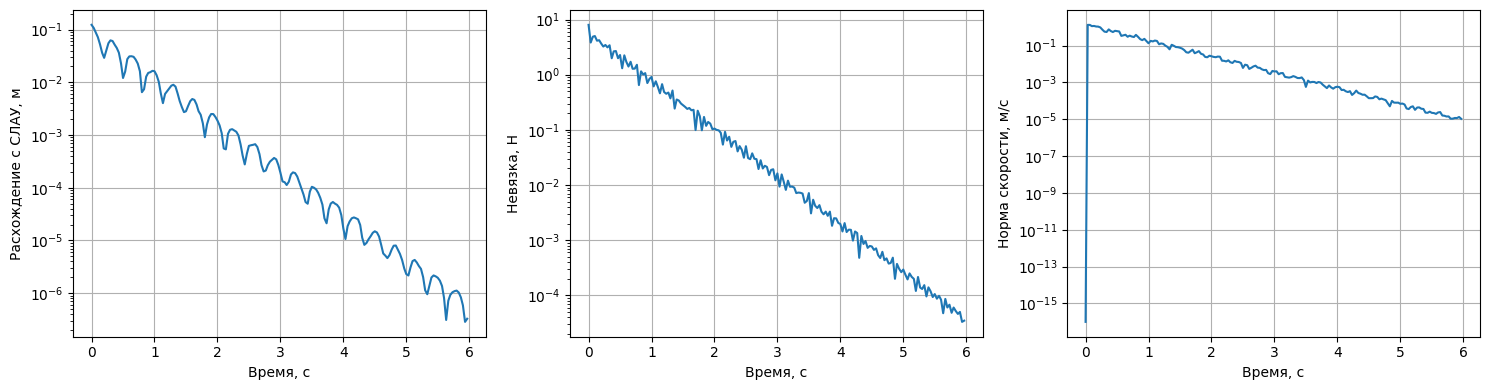

Относительное расхождение: 2.666879208972508e-06


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, values, label in zip(axes,
        [error_log, residual_log, velocity_log],
        ["Расхождение с СЛАУ, м", "Невязка, Н", "Норма скорости, м/с"]):
    ax.semilogy(time_log, np.maximum(values, 1e-16))
    ax.set(xlabel="Время, с", ylabel=label)
    ax.grid()
plt.tight_layout()
plt.show()
print("Относительное расхождение:",
      np.linalg.norm(grid_data.qpos-u_static)/np.linalg.norm(u_static))


## А4. Численные эксперименты с СЛАУ
Для каждого эксперимента укажите параметры, представьте график или таблицу и объясните результат.

1. **Масштабируемость.** Решётки $5\times5$, $10\times10$, $20\times20$. Сравните время прямых методов и число итераций. Для больших задач видео строить необязательно.
2. **Несколько нагрузок.** Подготовьте не менее 10 правых частей при одной $K$. Отдельно измерьте время разложения и последующих решений для LU и Холецкого; сравните с повторным применением метода Гаусса.
3. **Начальный вектор.** Как начальные условия используйте нулевой, случайный единичной нормы и близкий к эталонному решению. Постройте ошибку и невязку по итерациям. Для графика ошибки добавьте сохранение приближений, не меняя основной интерфейс функции.
4. **Чувствительность.** Изменяйте $k_0$ при фиксированных размере и $k_c$. Сопоставьте число обусловленности $\nu(K)$, число итераций и изменение решения при малом возмущении $f$. Повторите для нескольких направлений возмущения.
5. **Свободная решётка.** Рассмотрите $k_0=0$. Объясните вырожденность и существование равновесия в зависимости от суммарной нагрузки. Не пытайтесь интерпретировать огромные числа от решателя как корректное единственное решение.

При изменении параметров заново собирайте матрицу и XML-модель. Для удобства можете вынести сборку решётки в функцию.


In [ ]:
# TODO А4: код экспериментов, графики и таблицы.

def build_grid(side, k0=15.0, kc=40.0):
    """Собирает матрицу K и вектор сил f для решетки side x side.
    Та же логика, что в ячейке модели выше, только для любых параметров."""
    n_g = side**2

    def idx(row, col):
        return row * side + col

    K_g = k0 * np.eye(n_g)
    edges_g = []
    for row in range(side):
        for col in range(side):
            i = idx(row, col)
            if col + 1 < side:
                edges_g.append((i, idx(row, col + 1)))
            if row + 1 < side:
                edges_g.append((i, idx(row + 1, col)))

    for i, j in edges_g:
        K_g[i, i] += kc
        K_g[j, j] += kc
        K_g[i, j] -= kc
        K_g[j, i] -= kc

    f_g = np.zeros(n_g)
    f_g[idx(side // 2, side // 2)] = 8.0
    return K_g, f_g


def measure(fn, repeats=5):
    """Запускает fn() несколько раз и возвращает МЕДИАНУ времени в мс."""
    times = []
    for _ in range(repeats):
        t0 = perf_counter()
        fn()
        times.append((perf_counter() - t0) * 1000)
    return np.median(times)


rng = np.random.default_rng(42)

In [ ]:
#Экспримент 1
print(f"{'Решетка':<9} | {'n':>4} | {'Гаусс, мс':>10} | {'LU, мс':>8} | {'Холецкий, мс':>12} | {'Итер. Якоби':>11} | {'Итер. Зейдель':>13}")
print("-" * 86)

for side in [5, 10, 20]:
    K_e, f_e = build_grid(side)

    t_gauss = measure(lambda: gauss(K_e, f_e))
    t_lu    = measure(lambda: lu_solve(lu_factor(K_e), f_e))
    t_chol  = measure(lambda: cholesky_solve(K_e, f_e))

    _, r_jac = iterative_solve(K_e, f_e, "jacobi")
    _, r_sei = iterative_solve(K_e, f_e, "seidel")

    print(f"{str(side)+'x'+str(side):<9} | {side**2:>4} | {t_gauss:>10.1f} | {t_lu:>8.1f} | {t_chol:>12.1f} | {len(r_jac)-1:>11} | {len(r_sei)-1:>13}")

Решетка   |    n |  Гаусс, мс |   LU, мс | Холецкий, мс | Итер. Якоби | Итер. Зейдель
--------------------------------------------------------------------------------------
5x5       |   25 |        3.5 |      2.3 |          1.9 |         179 |            89
10x10     |  100 |       34.6 |     31.6 |         23.3 |         193 |            97
20x20     |  400 |      370.8 |    282.6 |        190.4 |         197 |           100


In [ ]:
#Эксперимент 2
K_e, _ = build_grid(20)
n_loads = 10
F_e = rng.normal(size=(K_e.shape[0], n_loads))   # 10 случайных нагрузок (столбцы)

def gauss_10_times():
    for k in range(n_loads):
        gauss(K_e, F_e[:, k])

t_gauss_total = measure(gauss_10_times)

# LU: разложение отдельно, решения отдельно
t_lu_factor = measure(lambda: lu_factor(K_e))
lu_factors = lu_factor(K_e)
t_lu_solves = measure(lambda: [lu_solve(lu_factors, F_e[:, k]) for k in range(n_loads)])

# Холецкий: разложение отдельно, решения отдельно
t_chol_factor = measure(lambda: cholesky_factor(K_e))
L_chol = cholesky_factor(K_e)
t_chol_solves = measure(lambda: [backward_substitution(L_chol.T, forward_substitution(L_chol, F_e[:, k]))
                                 for k in range(n_loads)])

print(f"Гаусс, 10 раз с нуля:         {t_gauss_total:8.1f} мс")
print(f"LU:       разложение {t_lu_factor:7.1f} мс + 10 решений {t_lu_solves:6.1f} мс = {t_lu_factor + t_lu_solves:8.1f} мс")
print(f"Холецкий: разложение {t_chol_factor:7.1f} мс + 10 решений {t_chol_solves:6.1f} мс = {t_chol_factor + t_chol_solves:8.1f} мс")

Гаусс, 10 раз с нуля:           3415.2 мс
LU:       разложение   513.1 мс + 10 решений   33.7 мс =    546.8 мс
Холецкий: разложение   205.5 мс + 10 решений   32.2 мс =    237.7 мс


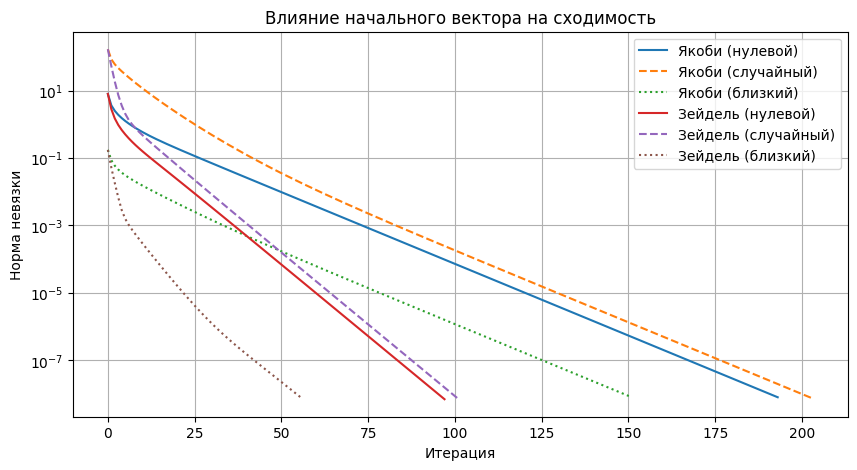

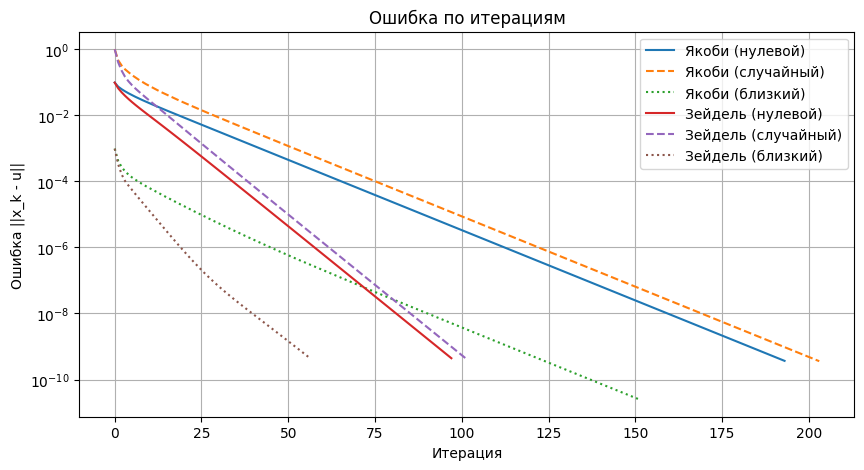

Итерации (нулевой / случайный / близкий):
  Якоби:   193 203 151
  Зейдель: 97 101 56


In [ ]:
#Эксперимент 3
side = 10
K, f = build_grid(side)
n = side**2

# списки h - в них функция сохраняет все приближения (для графика ошибки)
h_jac_zero, h_sei_zero = [], []
h_jac_rand, h_sei_rand = [], []
h_jac_close, h_sei_close = [], []

#Нулевой вектор
x0_zero = np.zeros(n)
_, r_jac_zero = iterative_solve(K, f, "jacobi", x0=x0_zero, history=h_jac_zero)
_, r_sei_zero = iterative_solve(K, f, "seidel", x0=x0_zero, history=h_sei_zero)

#Случайный, единичной нормы
x0_rand = np.random.randn(n)
x0_rand /= np.linalg.norm(x0_rand)
_, r_jac_rand = iterative_solve(K, f, "jacobi", x0=x0_rand, history=h_jac_rand)
_, r_sei_rand = iterative_solve(K, f, "seidel", x0=x0_rand, history=h_sei_rand)

# Близкий к эталону (решение Гаусса + шум 1% от нормы решения)
u_exact = gauss(K, f)
noise = np.random.randn(n)
x0_close = u_exact + 0.01 * np.linalg.norm(u_exact) * noise / np.linalg.norm(noise)   # ИЗМЕНЕНО: было 0.05*randn
_, r_jac_close = iterative_solve(K, f, "jacobi", x0=x0_close, history=h_jac_close)
_, r_sei_close = iterative_solve(K, f, "seidel", x0=x0_close, history=h_sei_close)

plt.figure(figsize=(10, 5))
plt.semilogy(r_jac_zero, label="Якоби (нулевой)")
plt.semilogy(r_jac_rand, '--', label="Якоби (случайный)")
plt.semilogy(r_jac_close, ':', label="Якоби (близкий)")
plt.semilogy(r_sei_zero, label="Зейдель (нулевой)")
plt.semilogy(r_sei_rand, '--', label="Зейдель (случайный)")
plt.semilogy(r_sei_close, ':', label="Зейдель (близкий)")
plt.xlabel("Итерация")
plt.ylabel("Норма невязки")
plt.legend()
plt.grid()
plt.title("Влияние начального вектора на сходимость")
plt.show()

#такой же график, но для ошибки ||x_k - u_exact||
def errors(hist):
    return [np.linalg.norm(xk - u_exact) for xk in hist]

plt.figure(figsize=(10, 5))
plt.semilogy(errors(h_jac_zero), label="Якоби (нулевой)")
plt.semilogy(errors(h_jac_rand), '--', label="Якоби (случайный)")
plt.semilogy(errors(h_jac_close), ':', label="Якоби (близкий)")
plt.semilogy(errors(h_sei_zero), label="Зейдель (нулевой)")
plt.semilogy(errors(h_sei_rand), '--', label="Зейдель (случайный)")
plt.semilogy(errors(h_sei_close), ':', label="Зейдель (близкий)")
plt.xlabel("Итерация")
plt.ylabel("Ошибка ||x_k - u||")
plt.legend()
plt.grid()
plt.title("Ошибка по итерациям")
plt.show()

# число итераций в цифрах
print("Итерации (нулевой / случайный / близкий):")
print("  Якоби:  ", len(r_jac_zero) - 1, len(r_jac_rand) - 1, len(r_jac_close) - 1)
print("  Зейдель:", len(r_sei_zero) - 1, len(r_sei_rand) - 1, len(r_sei_close) - 1)

In [ ]:
#Эксперимент 4
side = 10
k0_val = [100.0, 10.0, 1.0, 0.1, 0.01]

# столбцы с итерациями, возмущений теперь 3
print(f"{'k0':<8} | {'cond(K)':<12} | {'Итер. Якоби':<12} | {'Итер. Зейдель':<13} | {'Ошибка при 3 разных возмущениях f':<30}")
print("-" * 90)

# число итераций, а если не сошлось - текст вместо падения
def count_iter(K, f, method):
    try:
        _, r = iterative_solve(K, f, method, max_iter=50000)
        return len(r) - 1
    except RuntimeError:
        return "> 50000"

for k0 in k0_val:
    K, f = build_grid(side, k0=k0)
    #Проверка Обусловленности
    cond_K = np.linalg.cond(K)

    # Эталон
    u_exact = gauss(K, f)

    # 3 разных возмущения f на 0.1% вместо одного
    rel_errors = []
    for _ in range(3):
        f_perturbed = f + 0.001 * np.linalg.norm(f) * np.random.randn(len(f))
        u_perturbed = gauss(K, f_perturbed)
        rel_errors.append(np.linalg.norm(u_perturbed - u_exact) / np.linalg.norm(u_exact))

    errors_str = ", ".join(f"{e:.2e}" for e in rel_errors)
    print(f"{k0:<8} | {cond_K:12.2e} | {count_iter(K, f, 'jacobi')!s:<12} | {count_iter(K, f, 'seidel')!s:<13} | {errors_str}")

k0       | cond(K)      | Итер. Якоби  | Итер. Зейдель | Ошибка при 3 разных возмущениях f
------------------------------------------------------------------------------------------
100.0    |     4.12e+00 | 38           | 22            | 9.92e-03, 1.02e-02, 1.14e-02
10.0     |     3.22e+01 | 284          | 141           | 1.22e-02, 1.01e-02, 1.42e-02
1.0      |     3.13e+02 | 2718         | 1336          | 4.95e-03, 1.14e-02, 2.00e-02
0.1      |     3.12e+03 | 27056        | 13290         | 2.07e-02, 1.73e-03, 4.65e-03
0.01     |     3.12e+04 | > 50000      | > 50000       | 1.56e-02, 5.59e-03, 1.00e-02


In [ ]:
#Эксперимент 5
side = 5
K_free, f_free = build_grid(side, k0=0.0)

print(f"Определитель K (k0=0): {np.linalg.det(K_free):.2e}")
print(f"Минимальное собственное число: {np.linalg.eigvalsh(K_free)[0]:.2e}")
print(f"Число обусловленности: {np.linalg.cond(K_free):.2e}")
print(f"Сумма внешних сил: {np.sum(f_free)}")

# почему вырождена - сдвиг всей решетки на одно и то же ничего не растягивает
print(f"|K * (1,1,...,1)| = {np.linalg.norm(K_free @ np.ones(side**2)):.2e}")

try:
    u_free = gauss(K_free, f_free)
    print("Гаусс нашел решение (но оно может быть мусором из-за ошибок округления).")
    print(f"Максимальное смещение: {np.max(np.abs(u_free)):.2e}")
except np.linalg.LinAlgError:
    print("Гаусс выбросил исключение: матрица вырождена.")

# нагрузка с нулевой суммой сил (центр вниз, угол вверх)
f_balanced = np.zeros(side**2)
f_balanced[side**2 // 2] = 8.0
f_balanced[0] = -8.0
print(f"\nУравновешенная нагрузка, сумма сил: {np.sum(f_balanced)}")
try:
    u_bal, _ = iterative_solve(K_free, f_balanced, "seidel")
    print("Зейдель нашел решение, невязка:", np.linalg.norm(K_free @ u_bal - f_balanced))
    print("Сдвинули всю решетку на 0.3 м, невязка:", np.linalg.norm(K_free @ (u_bal + 0.3) - f_balanced))
    print("-> решение есть, но не единственное")
except RuntimeError:
    print("Зейдель не сошелся")

#  возвращаем исходные K, f, n, чтобы ячейки А3 (видео) работали и после экспериментов
K, f = build_grid(SIDE, k0=K_SUPPORT, kc=K_COUPLING)
n = SIDE**2

Определитель K (k0=0): -6.69e+33
Минимальное собственное число: -2.85e-16
Число обусловленности: 7.32e+16
Сумма внешних сил: 8.0
|K * (1,1,...,1)| = 0.00e+00
Гаусс выбросил исключение: матрица вырождена.

Уравновешенная нагрузка, сумма сил: 0.0
Зейдель нашел решение, невязка: 1.1175323159151652e-08
Сдвинули всю решетку на 0.3 м, невязка: 1.1175320842046835e-08
-> решение есть, но не единственное


Выводы А3-А4

А3. Проверка физической симуляцией. MuJoCo решает уравнение движения $M\ddot u + C\dot u + Ku = f$. За счет демпфирования колебания площадок затухают: на графиках в логарифмической шкале расхождение с решением СЛАУ, невязка и скорость убывают почти по прямой, то есть экспоненциально. Когда движение останавливается ($\ddot u = \dot u = 0$), остается $Ku = f$, поэтому установившееся положение совпадает с решением СЛАУ, и площадки ложатся на красные метки. Убывание невязки здесь вызвано физическим затуханием, а не работой численного метода. Это подтверждает и корректность решателей, и то, что матрица $K$ правильно описывает механическую систему. В сравнении на одной нагрузке прямые методы дают расхождение с эталоном порядка машинной точности, итерационные - порядка заданного допуска rtol.

А4.1. Масштабируемость. Время прямых методов при росте $n$ в 4 раза растет примерно в 16 раз, а не в 64, как следует из оценки $O(n^3)$: при таких размерах основное время уходит на циклы Python (их порядка $n^2$), а не на арифметику; при больших $n$ проявится кубический рост. Холецкий быстрее Гаусса и LU, так как использует симметрию и вычисляет только половину матрицы. Число итераций почти не зависит от размера (около 190 у Якоби и 95 у Зейделя): скорость сходимости определяется спектральным радиусом матрицы итерации, который для этой решетки близок к $4k_c/(k_0 + 4k_c) \approx 0.91$ при любом размере. Зейдель сходится примерно вдвое быстрее Якоби: для таких матриц его спектральный радиус равен квадрату спектрального радиуса Якоби.

А4.2. Несколько нагрузок. Метод Гаусса для каждой правой части заново приводит матрицу к треугольному виду ($O(n^3)$ на каждое решение). LU и Холецкий выполняют разложение один раз, а каждое следующее решение сводится к двум треугольным подстановкам ($O(n^2)$). Поэтому 10 решений через готовое разложение оказываются примерно на порядок быстрее десяти запусков Гаусса. Это типичная ситуация: конструкция (матрица) одна, нагрузки разные.

А4.3. Начальный вектор. В логарифмической шкале графики ошибки и невязки для всех стартов почти параллельны: сходимость линейная, на каждой итерации ошибка уменьшается примерно в одно и то же число раз $\rho$, а $\rho$ - свойство матрицы, а не начального приближения. Начальный вектор определяет только начальную ошибку, а значит, сколько раз ее нужно уменьшить: число итераций примерно равно $\log(e_0/\varepsilon)/\log(1/\rho)$. Случайный старт с нормой 1 примерно в 10 раз дальше от решения, чем нулевой, и требует больше итераций; старт с ошибкой 1% от решения - меньше. Хороший старт экономит лишь часть итераций, так как зависимость логарифмическая.

А4.4. Чувствительность. Минимальное собственное число $K$ равно $k_0$ (сдвиг всей решетки целиком деформирует только опоры), а максимальное от $k_0$ почти не зависит, поэтому $\nu(K) \sim 1/k_0$: при уменьшении $k_0$ в 10 раз число обусловленности растет в 10 раз. Число итераций растет пропорционально: диагональное преобладание ослабевает ($k_0 + 4k_c$ против $4k_c$), спектральный радиус матрицы итерации приближается к 1, и при $k_0 = 0.01$ методы не укладываются в 50 000 итераций. Относительная ошибка решения при возмущении $f$ ограничена сверху величиной $\nu(K) \cdot \|\Delta f\|/\|f\|$, но фактически для случайных возмущений она остается того же порядка, что и само возмущение, и не растет вместе с $\nu(K)$. Оценка через число обусловленности описывает худший случай (возмущение вдоль собственного вектора с наименьшим собственным числом, то есть сдвиг всей решетки), а случайное возмущение почти не попадает в это направление.

А4.5. Свободная решетка. При $k_0 = 0$ одинаковый сдвиг всех площадок не растягивает ни одной связи: $K \cdot (1, \dots, 1)^\top = 0$, поэтому матрица вырождена, ее наименьшее собственное число равно нулю с точностью округления. Внутренние пружины действуют попарно и в сумме дают нулевую силу, поэтому равновесие возможно только при нулевой суммарной внешней нагрузке. При исходной нагрузке (8 Н) равновесия нет: решетка как целое уходит вниз, и все решатели корректно отказываются (Гаусс сообщает о вырожденности, итерационные методы не сходятся). При уравновешенной нагрузке (сумма сил 0) равновесие существует, но не единственно: к любому решению можно прибавить одинаковый сдвиг всех площадок. Метод Зейделя находит одно из этих решений, и после сдвига всей решетки на 0.3 м невязка не меняется. Определитель, напечатанный для вырожденной матрицы, огромен (порядка $10^{33}$), а не равен нулю: это результат ошибок округления, поэтому по определителю судить о вырожденности нельзя, правильный признак - наименьшее собственное число или число обусловленности порядка $10^{16}$.



## А5. Контрольные матрицы: обусловленность и расходимость
1. Для матриц Гильберта $H_{ij}=1/(i+j-1)$ размеров $5,7,9,12$ задайте $x_*=\mathbf1$, $b=Hx_*$. Сравните методы Гаусса, LU и Холецкого **на одной матрице $H$**. Вычислите ошибку, невязку и число обусловленности. Корректно зафиксируйте отказ разложения, если округления мешают его выполнению.
2. Отдельно рассмотрите $A=H^\top H$, $b=Ax^*$. Объясните, почему переход к этой матрице усиливает проблему обусловленности.
3. Для положительно определенной матрицы с преобладающей диагональю  $A=B^\top B+\alpha I$ (если $\alpha$ достаточно большое) при $n=100,300$ сравните прямые методы; при $n=500$ исследуйте методы Якоби и Зейделя.


In [ ]:
def hilbert(m):
    """Матрица Гильберта m x m: H[i, j] = 1 / (i + j - 1), если считать с единицы."""
    H = np.zeros((m, m))
    for i in range(m):
        for j in range(m):
            H[i, j] = 1 / (i + j + 1)      # в Python индексы с нуля, поэтому +1, а не -1
    return H


def try_solve(solver, A, b):
    """Пробует решить систему. Возвращает ответ или None, если метод отказался."""
    try:
        return solver(A, b)
    except (np.linalg.LinAlgError, ValueError) as e:
        return None


methods = [
    ("Гаусс", gauss),
    ("LU", lambda A, b: lu_solve(lu_factor(A), b)),
    ("Холецкий", cholesky_solve),
]


def compare_methods(A, x_true):
    """Решает A x = b тремя методами и печатает ошибку и невязку каждого."""
    b = A @ x_true
    for name, solver in methods:
        x = try_solve(solver, A, b)
        if x is None:
            print(f"   {name:9s}: ОТКАЗ (разложение не выполнилось из-за округлений)")
        else:
            error = np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
            residual = np.linalg.norm(A @ x - b)
            print(f"   {name:9s}: ошибка = {error:.2e}, невязка = {residual:.2e}")

In [ ]:
#Эксперимент 1: матрица Гильберта
print("ЭКСПЕРИМЕНТ 1. Матрица Гильберта H, x* = (1, ..., 1), b = H x*\n")
for m in [5, 7, 9, 12]:
    H = hilbert(m)
    print(f"Размер {m}: cond(H) = {np.linalg.cond(H):.2e}")
    compare_methods(H, np.ones(m))

ЭКСПЕРИМЕНТ 1. Матрица Гильберта H, x* = (1, ..., 1), b = H x*

Размер 5: cond(H) = 4.77e+05
   Гаусс    : ошибка = 3.49e-13, невязка = 5.21e-16
   LU       : ошибка = 3.71e-13, невязка = 5.09e-16
   Холецкий : ошибка = 2.84e-12, невязка = 1.11e-16
Размер 7: cond(H) = 4.75e+08
   Гаусс    : ошибка = 9.75e-09, невязка = 0.00e+00
   LU       : ошибка = 1.30e-08, невязка = 5.09e-16
   Холецкий : ошибка = 3.45e-09, невязка = 4.00e-16
Размер 9: cond(H) = 4.93e+11
   Гаусс    : ошибка = 3.14e-06, невязка = 3.51e-16
   LU       : ошибка = 1.47e-05, невязка = 6.08e-16
   Холецкий : ошибка = 6.70e-06, невязка = 4.84e-16
Размер 12: cond(H) = 1.75e+16
   Гаусс    : ошибка = 2.43e-01, невязка = 5.09e-16
   LU       : ошибка = 3.91e-02, невязка = 7.36e-16
   Холецкий : ошибка = 3.18e-03, невязка = 6.84e-16


In [ ]:
#Эксперимент 2: матрица H^T H
print("\nЭКСПЕРИМЕНТ 2. Матрица A = H^T H\n")
for m in [5, 7, 9, 12]:
    H = hilbert(m)
    A = H.T @ H
    print(f"Размер {m}: cond(H) = {np.linalg.cond(H):.2e},  cond(H^T H) = {np.linalg.cond(A):.2e}")
    compare_methods(A, np.ones(m))


ЭКСПЕРИМЕНТ 2. Матрица A = H^T H

Размер 5: cond(H) = 4.77e+05,  cond(H^T H) = 2.27e+11
   Гаусс    : ошибка = 1.17e-05, невязка = 0.00e+00
   LU       : ошибка = 1.25e-05, невязка = 4.44e-16
   Холецкий : ошибка = 1.38e-05, невязка = 5.44e-16
Размер 7: cond(H) = 4.75e+08,  cond(H^T H) = 1.59e+17
   Гаусс    : ОТКАЗ (разложение не выполнилось из-за округлений)
   LU       : ОТКАЗ (разложение не выполнилось из-за округлений)
   Холецкий : ошибка = 1.56e+00, невязка = 8.88e-16
Размер 9: cond(H) = 4.93e+11,  cond(H^T H) = 5.03e+17
   Гаусс    : ОТКАЗ (разложение не выполнилось из-за округлений)
   LU       : ОТКАЗ (разложение не выполнилось из-за округлений)
   Холецкий : ошибка = 2.62e+00, невязка = 1.13e-15
Размер 12: cond(H) = 1.75e+16,  cond(H^T H) = 5.14e+17
   Гаусс    : ОТКАЗ (разложение не выполнилось из-за округлений)
   LU       : ОТКАЗ (разложение не выполнилось из-за округлений)
   Холецкий : ОТКАЗ (разложение не выполнилось из-за округлений)


In [ ]:
#Эксперимент 3: большая положительно определенная матрица
print("\nЭКСПЕРИМЕНТ 3. A = B^T B + alpha I\n")
rng = np.random.default_rng(42)


def make_matrix(n, alpha_factor):
    """A = B^T B + alpha I. alpha подбираем так, чтобы было (или не было) диагональное преобладание.
    alpha_factor > 1 - преобладание есть, alpha_factor < 1 - его нет."""
    B = rng.normal(size=(n, n))
    M = B.T @ B
    off_diag_sum = np.sum(np.abs(M), axis=1) - np.abs(np.diag(M))
    alpha_min = np.max(off_diag_sum - np.diag(M))
    alpha = alpha_factor * alpha_min
    return M + alpha * np.eye(n), alpha


# 3а: прямые методы при n = 100 и 300
print("3а. Прямые методы (alpha с диагональным преобладанием)")
for n_a in [100, 300]:
    A, alpha = make_matrix(n_a, 1.1)
    x_true = np.ones(n_a)
    b = A @ x_true
    print(f"n = {n_a}, alpha = {alpha:.0f}, cond(A) = {np.linalg.cond(A):.2e}")
    for name, solver in methods:
        t0 = perf_counter()
        x = solver(A, b)
        t = (perf_counter() - t0) * 1000
        error = np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
        print(f"   {name:9s}: время = {t:8.1f} мс, ошибка = {error:.2e}")

# 3б: итерационные методы при n = 500, с преобладанием и без
print("\n3б. Итерационные методы, n = 500")
n_a = 500
for alpha_factor, title in [(1.1, "есть диагональное преобладание"),
                            (0.1, "НЕТ диагонального преобладания")]:
    A, alpha = make_matrix(n_a, alpha_factor)
    x_true = np.ones(n_a)
    b = A @ x_true
    print(f"alpha = {alpha:.0f} ({title}), cond(A) = {np.linalg.cond(A):.2e}")
    for method in ["jacobi", "seidel"]:
        try:
            x, res = iterative_solve(A, b, method, max_iter=2000)
            error = np.linalg.norm(x - x_true) / np.linalg.norm(x_true)
            print(f"   {method:7s}: сошелся за {len(res) - 1} итераций, ошибка = {error:.2e}")
        except (RuntimeError, FloatingPointError) as e:
            print(f"   {method:7s}: НЕ СОШЕЛСЯ ({type(e).__name__})")


ЭКСПЕРИМЕНТ 3. A = B^T B + alpha I

3а. Прямые методы (alpha с диагональным преобладанием)
n = 100, alpha = 930, cond(A) = 1.38e+00
   Гаусс    : время =     33.5 мс, ошибка = 5.52e-16
   LU       : время =     30.7 мс, ошибка = 4.38e-16
   Холецкий : время =     22.3 мс, ошибка = 2.49e-16
n = 300, alpha = 5212, cond(A) = 1.23e+00
   Гаусс    : время =    238.7 мс, ошибка = 8.15e-16
   LU       : время =    166.6 мс, ошибка = 6.26e-16
   Холецкий : время =    116.9 мс, ошибка = 3.38e-16

3б. Итерационные методы, n = 500
alpha = 10494 (есть диагональное преобладание), cond(A) = 1.19e+00
   jacobi : сошелся за 9 итераций, ошибка = 6.75e-10
   seidel : сошелся за 6 итераций, ошибка = 1.55e-10
alpha = 956 (НЕТ диагонального преобладания), cond(A) = 3.15e+00
   jacobi : НЕ СОШЕЛСЯ (RuntimeError)
   seidel : сошелся за 14 итераций, ошибка = 4.27e-10




**Выводы А5:**


Выводы А5

А5.1. Матрица Гильберта. Число обусловленности $H$ растет очень быстро: от $5 \cdot 10^5$ при размере 5 до $1.6 \cdot 10^{16}$ при размере 12. Все три метода ведут себя одинаково: относительная ошибка решения растет примерно как $\nu(H) \cdot \varepsilon_{\text{маш}}$, где $\varepsilon_{\text{маш}} \approx 10^{-16}$ (размер 5: ошибка $10^{-13}$, размер 9: $10^{-6}$, размер 12: $10^{-1}$, то есть 10-25%). При этом невязка у всех методов остается порядка $10^{-16}$. Это главный вывод: малая невязка не гарантирует точного решения, если матрица плохо обусловлена. Найденный $x$ почти идеально подходит в уравнение, но далек от истинного $x^* = \mathbf 1$. Причина не в методе, а в самой задаче: ошибки округления порядка $10^{-16}$ усиливаются в $\nu(H)$ раз. Поэтому все методы дают ошибки одного порядка, и выбор метода ситуацию не спасает.

А5.2. Матрица $H^\top H$. Число обусловленности возводится в квадрат: $\nu(H^\top H) = \nu(H)^2$, так как собственные числа $H^\top H$ равны квадратам собственных чисел симметричной матрицы $H$, а отношение квадратов равно квадрату отношения. Уже при размере 5 обусловленность $2 \cdot 10^{11}$, и ошибка выросла с $10^{-13}$ до $10^{-5}$. При размере 7 обусловленность $10^{17}$ превышает $1/\varepsilon_{\text{маш}}$: для машинной арифметики матрица неотличима от вырожденной. Гаусс и LU обнаруживают это и отказываются (главный элемент становится нулем с точностью округления). Холецкий формально выполняется, но выдает ответ с ошибкой в несколько сотен процентов при невязке $10^{-15}$, что опаснее отказа, результат выглядит правдоподобно. При размере 12 отказывает и Холецкий. Переход к $H^\top H$ (например, при решении задачи наименьших квадратов через нормальные уравнения) резко ухудшает обусловленность, поэтому для плохо обусловленных матриц его следует избегать.

А5.3. Матрица $B^\top B + \alpha I$. Значение $\alpha$ подбиралось так, чтобы обеспечить диагональное преобладание: $\alpha_{\min}$ равно наибольшему по строкам недостатку диагонального элемента до суммы модулей остальных элементов строки.

При $\alpha = 1.1\,\alpha_{\min}$ матрица хорошо обусловлена ($\nu(A) \approx 1.2$-$1.4$), и все три прямых метода при $n = 100$ и $n = 300$ дают ошибку порядка машинной точности ($10^{-16}$). Различаются они только временем: Холецкий быстрее Гаусса и LU, так как использует симметрию. При росте $n$ с 100 до 300 время растет примерно в 9 раз.

При n = 500 и диагональном преобладании оба итерационных метода сходятся за единицы итераций (Якоби 9, Зейдель 6): матрица близка к $\alpha I$, и спектральный радиус матрицы итерации мал. Когда $\alpha$ уменьшено до $0.1\,\alpha_{\min}$ и диагонального преобладания нет, метод Якоби не сходится, а метод Зейделя сходится за 14 итераций. Это согласуется с теорией: диагональное преобладание - достаточное условие сходимости обоих методов, а для симметричной положительно определенной матрицы (а $B^\top B + \alpha I$ именно такая при любом $\alpha > 0$) метод Зейделя сходится всегда, тогда как для метода Якоби это не гарантируется.

# Б. Обратная кинематика двухзвенного механизма
Решатели методом Гаусса или LU из части А теперь используется внутри нелинейного метода.


## 1. Модель механизма

Механизм состоит из двух звеньев длиной $l_1$ и $l_2$. Точка подвеса находится на высоте $z_0$. Движение происходит в вертикальной плоскости $xz$.

Обобщённые координаты:
- $q_1$ — угол первого звена относительно вертикали вниз;
- $q_2$ — угол второго звена относительно первого.

При $q_1=q_2=0$ оба звена направлены вертикально вниз.

В модели присутствуют гравитация, инерция и сопротивление в суставах. Два привода позволяют задавать моменты сил.


In [ ]:
L1 = L2 = 0.7
BASE_Z = 1.7

arm_xml = f"""
<mujoco model="double_pendulum">
  <option timestep="0.002"
          gravity="0 0 -9.81"
          integrator="implicitfast"/>

  <visual>
    <global offwidth="640" offheight="480"/>
    <headlight ambient="0.5 0.5 0.5"/>
  </visual>

  <default>
    <joint damping="0.15" armature="0.01"/>
    <geom contype="0" conaffinity="0"/>
  </default>

  <worldbody>
    <light pos="0 -3 4" dir="0 1 -1"/>
    <camera name="front" pos="0 -4 1.1"
            xyaxes="1 0 0 0 0 1"/>

    <geom type="plane" size="3 3 0.1"
          rgba="0.92 0.94 0.97 1"/>

    <geom type="sphere" pos="0 0 {BASE_Z}"
          size="0.065" rgba="0.2 0.2 0.25 1"/>

    <body name="link1" pos="0 0 {BASE_Z}">
      <joint name="q1" type="hinge" axis="0 -1 0"/>
      <geom type="capsule"
            fromto="0 0 0 0 0 {-L1}"
            size="0.035" mass="1"
            rgba="0.15 0.45 0.9 1"/>

      <body name="link2" pos="0 0 {-L1}">
        <joint name="q2" type="hinge" axis="0 -1 0"/>
        <geom type="sphere" size="0.05"
              rgba="0.2 0.2 0.25 1"/>
        <geom type="capsule"
              fromto="0 0 0 0 0 {-L2}"
              size="0.03" mass="0.7"
              rgba="0.1 0.7 0.6 1"/>
        <site name="tip" pos="0 0 {-L2}"
              size="0.045" rgba="1 0.25 0.3 1"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <motor joint="q1" gear="1"/>
    <motor joint="q2" gear="1"/>
  </actuator>
</mujoco>
"""

arm_model = mujoco.MjModel.from_xml_string(arm_xml)
arm_data = mujoco.MjData(arm_model)
tip_id = mujoco.mj_name2id(
    arm_model, mujoco.mjtObj.mjOBJ_SITE, "tip"
)

print("Число степеней свободы:", arm_model.nv)


Число степеней свободы: 2


## 2. Прямая и обратная кинематика

Прямая кинематика определяет положение конца механизма по углам:

$$
p(q)=
\begin{pmatrix}
l_1\sin q_1+l_2\sin(q_1+q_2)\\
z_0-l_1\cos q_1-l_2\cos(q_1+q_2)
\end{pmatrix}.
$$

В обратной задаче известна целевая точка $p_*$, а углы требуется найти:

$$
F(q)=p(q)-p_*=0.
$$

Решение может быть не единственным. Кроме того, целевая точка может оказаться недостижимой.

Без ограничений на углы условие достижимости:

$$
|l_1-l_2|\leq \|p_*-(0,z_0)^\top\|_2\leq l_1+l_2.
$$

### Метод Ньютона

В окрестности текущего приближения $q_k$ используем линеаризацию:

$$
F(q_k+\Delta q_k)\approx F(q_k)+J(q_k)\Delta q_k,
$$

где $J$ — матрица Якоби. Приравнивая линейное приближение к нулю, получаем СЛАУ:

$$
J(q_k)\Delta q_k=-F(q_k).
$$

После её решения обновляем углы:

$$
q_{k+1}=q_k+\Delta q_k.
$$

Таким образом, каждая итерация Ньютона включает решение СЛАУ. Явно вычислять обратную матрицу не требуется.

Для двухзвенного механизма:

$$
J(q)=
\begin{pmatrix}
l_1\cos q_1+l_2\cos(q_1+q_2) & l_2\cos(q_1+q_2)\\
l_1\sin q_1+l_2\sin(q_1+q_2) & l_2\sin(q_1+q_2)
\end{pmatrix}.
$$


## Б1. Реализация кинематики и метода Ньютона
Реализуйте `endpoint`, аналитический `jacobian` и `inverse_kinematics`.

Реализуйте метод Ньютона, проверяйте невязку, ограничивайте число шагов, корректно обрабатывайте сингулярную систему и невозможность подобрать шаг.

Возвращайте `(q, iterations)`, где `iterations` — число сделанных обновлений. Для исследования сохраняйте историю невязки, поправки и шага в собственной диагностической функции. Не вычисляйте обратную матрицу явно.


In [ ]:
from math import sin, cos

def endpoint(q):
    q1, q2 = q[0], q[1]
    l1, l2, z0 = L1, L2, BASE_Z
    p = np.array([l1 * sin(q1) + l2 * sin(q1 + q2), z0 - l1 * cos(q1) - l2 * cos(q1 + q2)])
    return p


def jacobian(q):
    q1, q2 = q[0], q[1]
    l1, l2 = L1, L2
    J = np.array([[l1 * cos(q1) + l2 * cos(q1 + q2), l2 * cos(q1 + q2)], [l1 * sin(q1) + l2 * sin(q1 + q2), l2 * sin(q1 + q2)]])
    return J


def solve_linear(A, b):
    return gauss(A, b)


def newton_ik(target, q0, tol=1e-9, max_iter=40):
    q = np.array(q0, dtype=float)
    p_t = np.array(target, dtype=float)
    history = {"residual": [], "step": [], "alpha": [], "cond": []}

    F = endpoint(q) - p_t
    norm = np.linalg.norm(F)
    history["residual"].append(norm)

    for k in range(max_iter):
        if norm < tol:
            return q, k, True, history

        J = jacobian(q)
        history["cond"].append(np.linalg.cond(J))
        try:
            delta_q = solve_linear(J, -F)
        except np.linalg.LinAlgError:
            return q, k, False, history


        alpha = 1.0
        while np.linalg.norm(endpoint(q + alpha * delta_q) - p_t) >= norm:
            alpha /= 2
            if alpha < 1e-4:
                return q, k, False, history

        q = q + alpha * delta_q
        F = endpoint(q) - p_t
        norm = np.linalg.norm(F)

        history["residual"].append(norm)
        history["step"].append(np.linalg.norm(alpha * delta_q))
        history["alpha"].append(alpha)

    return q, max_iter, norm < tol, history


def inverse_kinematics(target, q0, tol=1e-9, max_iter=40):
    # TODO Б1: метод Ньютона.
    # Возвращать (q, iterations), не изменять q0.
    q, iterations, converged, _ = newton_ik(target, q0, tol, max_iter)
    if not converged:
        raise RuntimeError(f"Ньютон не сошелся: цель {target}, старт {q0}")
    return q, iterations

In [ ]:
q_test = np.array([0.4, 1.2])
arm_data.qpos[:] = q_test
mujoco.mj_forward(arm_model, arm_data)
np.testing.assert_allclose(endpoint(q_test),
                          arm_data.site_xpos[tip_id][[0, 2]], atol=1e-10)
h = 1e-6
J_fd = np.column_stack([
    (endpoint(q_test+h*np.eye(2)[j])-endpoint(q_test-h*np.eye(2)[j]))/(2*h)
    for j in range(2)
])
np.testing.assert_allclose(jacobian(q_test), J_fd, atol=1e-7)
q_found, count = inverse_kinematics(endpoint(q_test), [0.3, 1.1])
assert np.linalg.norm(endpoint(q_found)-endpoint(q_test)) < 1e-8
print("Базовые проверки Б1 пройдены.")

Базовые проверки Б1 пройдены.


## 3. Расчёт заданных углов

Придумаем траекторию, чтобы манипулятор её исполнил. Сердечко задаётся параметрической кривой $p_*(t)$. Выбираем последовательность точек этой кривой и для каждой решаем обратную задачу кинематики.

Для первой точки задаём начальные углы вручную. Для следующих используем решение предыдущей задачи:

$$
q^{(0)}_{i+1}=q_i.
$$

При близких соседних точках это обычно сокращает число итераций и помогает сохранять одну ветвь решения.

На этом этапе мы рассчитываем **заданные углы**, а не физическое движение механизма.

Проверяем:
- достигнутую невязку;
- число итераций;
- непрерывность полученной последовательности углов.


Максимальная ошибка IK: 1.00e-09 м
Максимум итераций Ньютона: 4


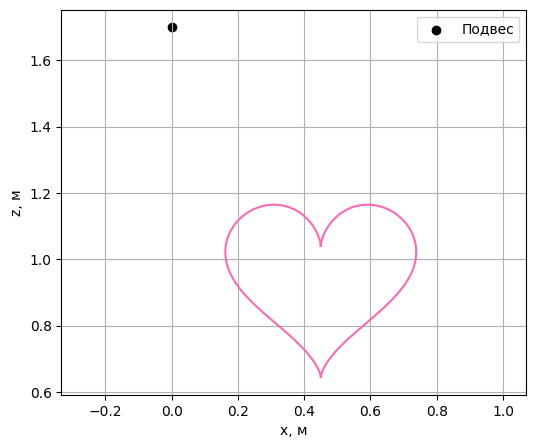

In [ ]:
def heart(phase):
    """Сердечко целиком внутри рабочей области."""
    x = 16*np.sin(phase)**3
    z = (
        13*np.cos(phase)
        - 5*np.cos(2*phase)
        - 2*np.cos(3*phase)
        - np.cos(4*phase)
    )
    return np.array([
        0.45 + 0.018*x,
        0.95 + 0.018*z,
    ])

ARM_FPS = 30
ARM_DURATION = 12.0
N = int(ARM_FPS * ARM_DURATION)

times = np.arange(N + 1) / ARM_FPS
phases = 2*np.pi * times / ARM_DURATION
targets = np.array([heart(phase) for phase in phases])

q_reference = []
iteration_counts = []

q_guess = np.array([-0.4, 1.7])

for target in targets:
    q_guess, iterations = inverse_kinematics(target, q_guess)
    q_reference.append(q_guess.copy())
    iteration_counts.append(iterations)

q_reference = np.array(q_reference)
dq_reference = np.gradient(q_reference, 1/ARM_FPS, axis=0)

ik_errors = np.linalg.norm(
    np.array([endpoint(q) for q in q_reference]) - targets,
    axis=1,
)

print(f"Максимальная ошибка IK: {ik_errors.max():.2e} м")
print(f"Максимум итераций Ньютона: {max(iteration_counts)}")

plt.figure(figsize=(6, 5))
plt.plot(targets[:, 0], targets[:, 1], color="hotpink")
plt.scatter(0, BASE_Z, color="black", label="Подвес")
plt.axis("equal")
plt.xlabel("x, м")
plt.ylabel("z, м")
plt.legend()
plt.grid()
plt.show()


## 4. Физическое воспроизведение траектории

Рассчитанные углы становятся заданием для PD-регулятора:

$$
\tau=
K_P(q_{\mathrm{зад}}-q)
+
K_D(\dot q_{\mathrm{зад}}-\dot q)
+
b(q,\dot q),
$$

где $b(q,\dot q)$ компенсирует гравитационные и скоростные силы модели.

Регулятор задаёт моменты в суставах, а MuJoCo рассчитывает движение.

На видео:
- розовые точки — заданная траектория;
- красная точка — текущая цель;
- зелёный след — фактическое движение конца механизма.

Промежуточные итерации Ньютона на этом видео не показаны: обратная кинематика рассчитана заранее.


In [ ]:
def reference_at(t):
    """Линейная интерполяция заданных углов и скоростей."""
    t = np.clip(t, 0.0, ARM_DURATION)

    q = np.array([
        np.interp(t, times, q_reference[:, j])
        for j in range(2)
    ])

    dq = np.array([
        np.interp(t, times, dq_reference[:, j])
        for j in range(2)
    ])

    return q, dq


def add_dot(scene, point, radius, color):
    if scene.ngeom >= scene.maxgeom:
        return

    geom = scene.geoms[scene.ngeom]
    mujoco.mjv_initGeom(
        geom,
        mujoco.mjtGeom.mjGEOM_SPHERE,
        np.array([radius, radius, radius]),
        np.asarray(point, dtype=float),
        np.eye(3).ravel(),
        np.asarray(color, dtype=np.float32),
    )
    scene.ngeom += 1


mujoco.mj_resetData(arm_model, arm_data)
arm_data.qpos[:] = q_reference[0]
arm_data.qvel[:] = dq_reference[0]
mujoco.mj_forward(arm_model, arm_data)

KP = np.array([180.0, 100.0])
KD = np.array([25.0, 12.0])

arm_frames = []
actual_points = []

arm_renderer = mujoco.Renderer(
    arm_model, height=480, width=640, max_geom=3000
)

try:
    for frame_time in times[:-1]:
        while arm_data.time < frame_time - 1e-10:
            q_desired, dq_desired = reference_at(arm_data.time)

            # qfrc_bias компенсирует гравитацию и скоростные силы.
            arm_data.ctrl[:] = (
                KP * (q_desired - arm_data.qpos)
                + KD * (dq_desired - arm_data.qvel)
                + arm_data.qfrc_bias
            )
            mujoco.mj_step(arm_model, arm_data)

        # Обновляем положения site для текущего состояния.
        mujoco.mj_forward(arm_model, arm_data)
        actual_points.append(arm_data.site_xpos[tip_id].copy())

        arm_renderer.update_scene(arm_data, camera="front")
        scene = arm_renderer.scene

        # Заданная траектория: розовые точки.
        for x, z in targets[::3]:
            add_dot(
                scene, [x, -0.025, z], 0.005,
                [1.0, 0.45, 0.65, 1.0]
            )

        # След реального конца маятника.
        for point in actual_points:
            p = point.copy()
            p[1] = -0.045
            add_dot(
                scene, p, 0.007,
                [0.1, 0.75, 0.3, 1.0]
            )

        # Текущая цель.
        target = heart(2*np.pi * frame_time / ARM_DURATION)
        add_dot(
            scene, [target[0], -0.07, target[1]],
            0.025, [1.0, 0.15, 0.2, 1.0]
        )

        arm_frames.append(arm_renderer.render().copy())
finally:
    arm_renderer.close()

actual_points = np.array(actual_points)

media.show_video(arm_frames, fps=ARM_FPS)


This browser does not support the video tag.


## 5. Анализ ошибок

Различаем две ошибки.

**Ошибка обратной кинематики:**

$$
e_{\mathrm{IK}}(t)=
\|p(q_{\mathrm{зад}}(t))-p_*(t)\|_2.
$$

Она характеризует точность найденных углов относительно целевой точки.

**Ошибка физического слежения:**

$$
e_{\mathrm{track}}(t)=
\|p(q_{\mathrm{факт}}(t))-p_*(t)\|_2.
$$

Она зависит от динамики механизма, регулятора и скорости движения.

Даже при точном решении обратной кинематики фактическая траектория может отличаться от заданной.

### Сингулярные конфигурации

Для нашего якобиана

$$
\det J(q)=l_1l_2\sin q_2.
$$

Когда звенья лежат на одной прямой, якобиан вырождается. Вблизи таких конфигураций небольшое изменение цели может требовать большого изменения углов.

Исследуйте, как приближение к сингулярности влияет на поправку Ньютона, число итераций и чувствительность решения.


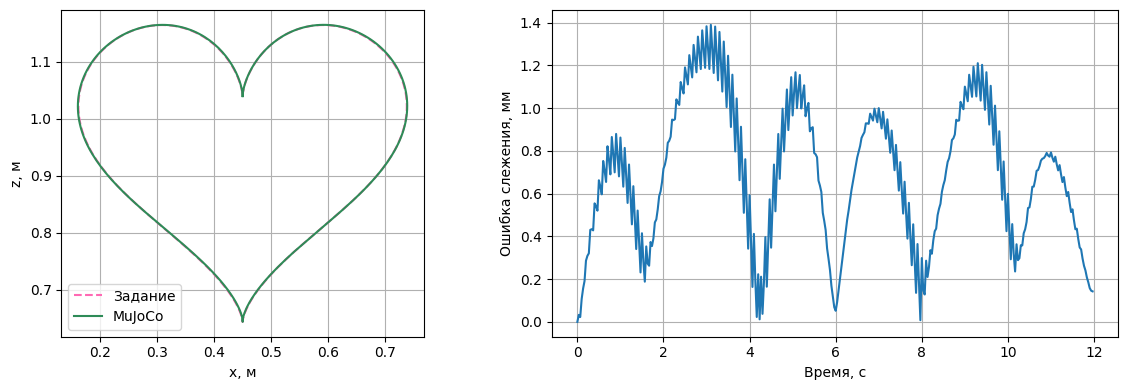

Средняя ошибка: 0.69 мм
Максимальная ошибка: 1.39 мм


In [ ]:
actual_xz = actual_points[:, [0, 2]]
tracking_error = np.linalg.norm(
    actual_xz - targets[:-1], axis=1
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    targets[:, 0], targets[:, 1],
    "--", color="hotpink", label="Задание"
)
axes[0].plot(
    actual_xz[:, 0], actual_xz[:, 1],
    color="seagreen", label="MuJoCo"
)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x, м")
axes[0].set_ylabel("z, м")
axes[0].legend()
axes[0].grid()

axes[1].plot(times[:-1], tracking_error * 1000)
axes[1].set_xlabel("Время, с")
axes[1].set_ylabel("Ошибка слежения, мм")
axes[1].grid()

plt.tight_layout()
plt.show()

print(f"Средняя ошибка: {tracking_error.mean()*1000:.2f} мм")
print(f"Максимальная ошибка: {tracking_error.max()*1000:.2f} мм")


## Б2–Б3. Исследование обратной кинематики
**Б2. Сходимость.** Для одной достижимой цели постройте карту по начальным углам $q_1,q_2\in[-\pi,\pi]$ (не менее $30\times30$ точек). Покажите число итераций, ветвь решения и неудачные старты. Углы сравнивайте с учётом периодичности $2\pi$.

Исследуйте недостижимую цель и цели около сингулярности. Постройте истории невязки, нормы поправки и числа обусловленности якобиана. Отличайте недостижимость от неудачи алгоритма при конкретном старте.

**Б3. Траектория.** Создайте собственную достижимую траекторию и воспроизведите её. Сравните минимум два времени обхода. Разделите ошибку IK в узлах траектории, погрешность интерполяции между узлами и ошибку физического слежения. Красная цель на видео должна соответствовать вашей новой траектории: замените `heart` в обоих местах или используйте единую функцию траектории.

Для исследования скорости сходимости используйте цель с невырожденным якобианом и достаточно близкий старт; квадратичная сходимость является локальным свойством.


In [ ]:
# Б2. Сходимость метода Ньютона

def wrap(angle):
    """Приводит угол к промежутку (-pi, pi]: углы 0.5 и 0.5 + 2pi - одно и то же положение."""
    return (angle + np.pi) % (2 * np.pi) - np.pi


def branch(q):
    """Ветвь решения: где локоть. +1 - sin(q2) > 0, -1 - sin(q2) < 0.
    Для одной точки обычно есть ровно два положения руки: локоть "в одну" или "в другую" сторону."""
    return 1 if np.sin(q[1]) > 0 else -1


def newton_plain(target, q0, tol=1e-9, max_iter=40):
    """Обычный метод Ньютона: всегда полный шаг, без уменьшения.
    Нужен, чтобы сравнить его с newton_ik (там шаг уменьшается)."""
    q = np.array(q0, dtype=float)
    p_t = np.array(target, dtype=float)
    for k in range(max_iter):
        F = endpoint(q) - p_t
        if np.linalg.norm(F) < tol:
            return q, k, True
        try:
            q = q + solve_linear(jacobian(q), -F)
        except np.linalg.LinAlgError:
            return q, k, False
    return q, max_iter, np.linalg.norm(endpoint(q) - p_t) < tol

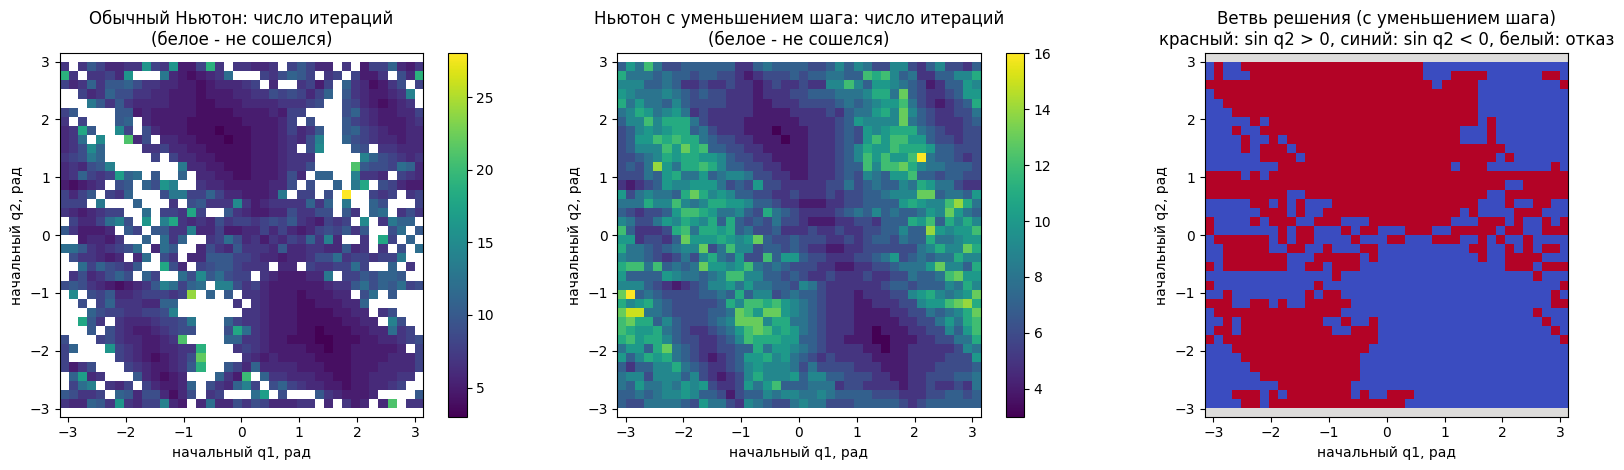

Цель [0.45 0.95], стартов: 1600
Обычный Ньютон:           не сошелся в 392 стартах, медиана итераций 7
С уменьшением шага:       не сошелся в 80 стартах, медиана итераций 7
Ветвь +1: 757 стартов, ветвь -1: 763 стартов


In [ ]:
# Б2.1. Карта сходимости по начальным углам

target_map = np.array([0.45, 0.95])
GRID = 40
q_values = np.linspace(-np.pi, np.pi, GRID)

iters_damped = np.full((GRID, GRID), np.nan)
iters_plain = np.full((GRID, GRID), np.nan)
branch_map = np.zeros((GRID, GRID))

for a, q1_start in enumerate(q_values):
    for c, q2_start in enumerate(q_values):
        q0 = [q1_start, q2_start]

        q, it, ok, _ = newton_ik(target_map, q0)
        if ok:
            iters_damped[c, a] = it
            branch_map[c, a] = branch(q)

        q, it, ok = newton_plain(target_map, q0)
        if ok:
            iters_plain[c, a] = it

extent = [-np.pi, np.pi, -np.pi, np.pi]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

im = axes[0].imshow(iters_plain, origin="lower", extent=extent, cmap="viridis")
axes[0].set_title("Обычный Ньютон: число итераций\n(белое - не сошелся)")
plt.colorbar(im, ax=axes[0])

im = axes[1].imshow(iters_damped, origin="lower", extent=extent, cmap="viridis")
axes[1].set_title("Ньютон с уменьшением шага: число итераций\n(белое - не сошелся)")
plt.colorbar(im, ax=axes[1])

im = axes[2].imshow(branch_map, origin="lower", extent=extent, cmap="coolwarm", vmin=-1, vmax=1)
axes[2].set_title("Ветвь решения (с уменьшением шага)\nкрасный: sin q2 > 0, синий: sin q2 < 0, белый: отказ")

for ax in axes:
    ax.set_xlabel("начальный q1, рад")
    ax.set_ylabel("начальный q2, рад")
plt.tight_layout()
plt.show()

total = GRID * GRID
print(f"Цель {target_map}, стартов: {total}")
print(f"Обычный Ньютон:           не сошелся в {np.isnan(iters_plain).sum()} стартах, "
      f"медиана итераций {np.nanmedian(iters_plain):.0f}")
print(f"С уменьшением шага:       не сошелся в {np.isnan(iters_damped).sum()} стартах, "
      f"медиана итераций {np.nanmedian(iters_damped):.0f}")
print(f"Ветвь +1: {(branch_map == 1).sum()} стартов, ветвь -1: {(branch_map == -1).sum()} стартов")

обычная цель (центр сердечка): расстояние 0.875 м, достижима: True, сошелся: True, итераций: 5, итоговая невязка: 1.19e-14
около сингулярности (99.9% вылета): расстояние 1.399 м, достижима: True, сошелся: True, итераций: 7, итоговая невязка: 1.12e-11
недостижимая (110% вылета): расстояние 1.540 м, достижима: False, сошелся: False, итераций: 6, итоговая невязка: 1.47e-01


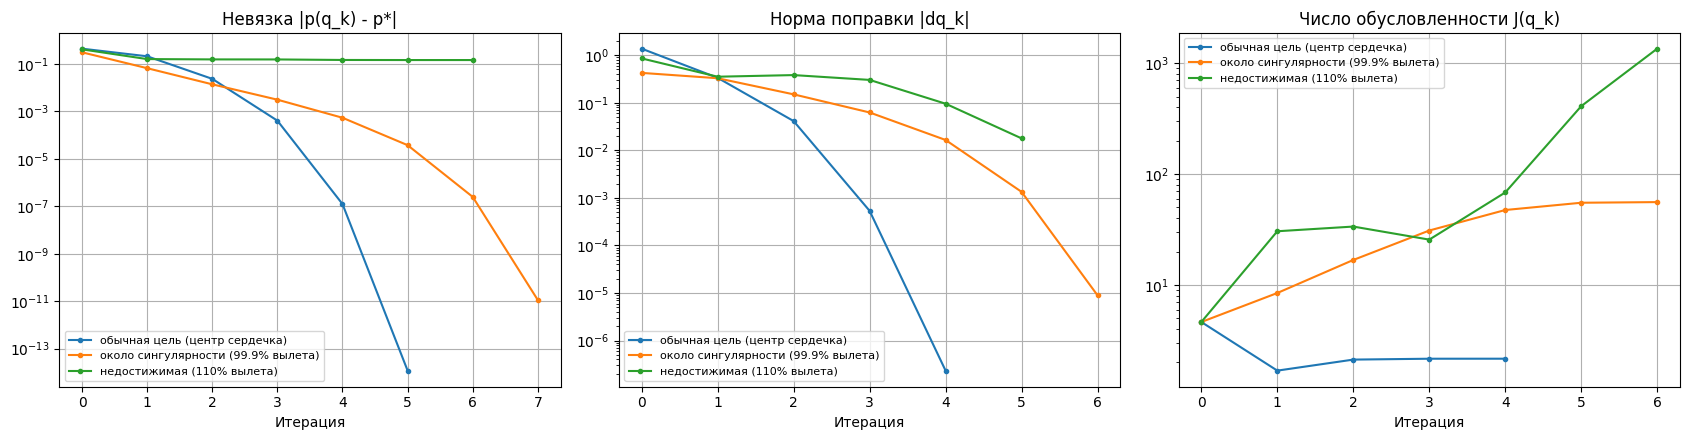

In [ ]:
# Б2.2. Обычная, почти сингулярная и недостижимая цели

base = np.array([0.0, BASE_Z])
direction = np.array([np.sin(0.6), -np.cos(0.6)])
reach = L1 + L2

cases = [
    ("обычная цель (центр сердечка)",     np.array([0.45, 0.95])),
    ("около сингулярности (99.9% вылета)", base + 0.999 * reach * direction),
    ("недостижимая (110% вылета)",        base + 1.10 * reach * direction),
]
q_start = [0.3, 1.0]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, target in cases:
    distance = np.linalg.norm(target - base)
    reachable = abs(L1 - L2) <= distance <= L1 + L2
    q, it, ok, hist = newton_ik(target, q_start, max_iter=40)
    print(f"{name}: расстояние {distance:.3f} м, достижима: {reachable}, "
          f"сошелся: {ok}, итераций: {it}, итоговая невязка: {hist['residual'][-1]:.2e}")

    axes[0].semilogy(hist["residual"], "o-", ms=3, label=name)
    axes[1].semilogy(hist["step"], "o-", ms=3, label=name)
    axes[2].semilogy(hist["cond"], "o-", ms=3, label=name)

axes[0].set(title="Невязка |p(q_k) - p*|", xlabel="Итерация")
axes[1].set(title="Норма поправки |dq_k|", xlabel="Итерация")
axes[2].set(title="Число обусловленности J(q_k)", xlabel="Итерация")
for ax in axes:
    ax.grid()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [ ]:
# Б2.3. Квадратичная сходимость

q_true = np.array([0.4, 1.2])
target_q = endpoint(q_true)
q, it, ok, hist = newton_ik(target_q, [0.3, 1.1])
r = hist["residual"]
print("\nКвадратичная сходимость: невязки по итерациям")
for k in range(len(r)):
    ratio = f"  r_k / r_(k-1)^2 = {r[k] / r[k-1]**2:.2f}" if k > 0 and r[k] > 1e-14 else ""
    print(f"  k = {k}: r = {r[k]:.2e}{ratio}")


Квадратичная сходимость: невязки по итерациям
  k = 0: r = 1.80e-01
  k = 1: r = 1.70e-02  r_k / r_(k-1)^2 = 0.52
  k = 2: r = 2.48e-04  r_k / r_(k-1)^2 = 0.86
  k = 3: r = 5.60e-08  r_k / r_(k-1)^2 = 0.91
  k = 4: r = 3.09e-15


Расстояние от подвеса: от 0.58 до 1.19 м (допустимо от 0.00 до 1.40 м)


This browser does not support the video tag.



Время обхода 12 с: максимум итераций Ньютона 3
   ошибка IK в узлах:          макс 9.94e-10 м
   ошибка интерполяции:        макс 0.0355 мм
   ошибка физического слежения: средняя 0.42 мм, макс 1.01 мм

Время обхода 4 с: максимум итераций Ньютона 3
   ошибка IK в узлах:          макс 6.69e-10 м
   ошибка интерполяции:        макс 0.3193 мм
   ошибка физического слежения: средняя 3.30 мм, макс 8.35 мм


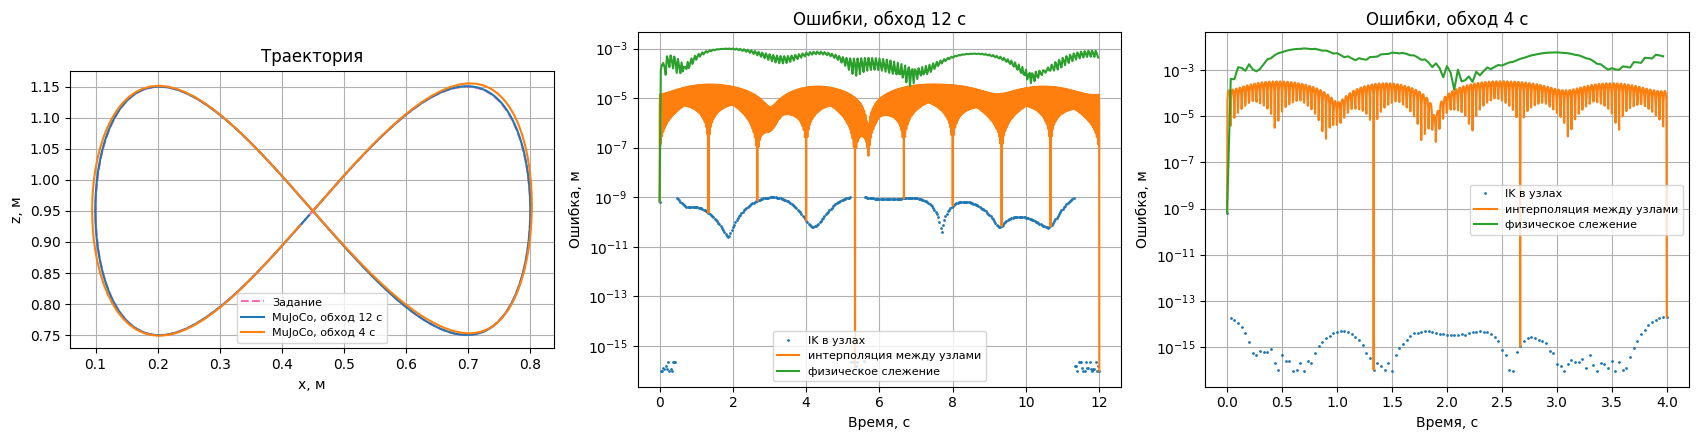

In [ ]:
# Б3. Собственная траектория: восьмерка

def eight(phase):
    """Восьмерка (лемниската) внутри рабочей области манипулятора."""
    return np.array([
        0.45 + 0.35 * np.sin(phase),
        0.95 + 0.20 * np.sin(phase) * np.cos(phase) * 2,
    ])

# Проверка достижимости: каждая точка должна быть не дальше L1 + L2 от подвеса
check_phases = np.linspace(0, 2 * np.pi, 400)
distances = [np.linalg.norm(eight(ph) - np.array([0.0, BASE_Z])) for ph in check_phases]
print(f"Расстояние от подвеса: от {min(distances):.2f} до {max(distances):.2f} м "
      f"(допустимо от {abs(L1 - L2):.2f} до {L1 + L2:.2f} м)")


def compute_reference(trajectory, duration, fps=30, q_start=(-0.4, 1.7)):
    """Узлы траектории и заданные углы (как в ячейке с сердечком, только для любой траектории)."""
    n_nodes = int(fps * duration)
    times_r = np.arange(n_nodes + 1) / fps
    targets_r = np.array([trajectory(2 * np.pi * t / duration) for t in times_r])

    q_ref, iters = [], []
    q_guess = np.array(q_start)
    for target in targets_r:
        q_guess, it = inverse_kinematics(target, q_guess)
        q_ref.append(q_guess.copy())
        iters.append(it)
    q_ref = np.array(q_ref)
    dq_ref = np.gradient(q_ref, 1 / fps, axis=0)

    e_ik = np.linalg.norm(np.array([endpoint(q) for q in q_ref]) - targets_r, axis=1)
    return times_r, targets_r, q_ref, dq_ref, e_ik, iters


def interpolation_error(trajectory, duration, times_r, q_ref, factor=10):
    """Между узлами регулятор получает углы линейной интерполяцией.
    Сравниваем, куда попадает кончик при интерполированных углах, с точной кривой."""
    t_fine = np.linspace(0, duration, factor * len(times_r))
    errors = []
    for t in t_fine:
        q_interp = np.array([np.interp(t, times_r, q_ref[:, j]) for j in range(2)])
        errors.append(np.linalg.norm(endpoint(q_interp) - trajectory(2 * np.pi * t / duration)))
    return t_fine, np.array(errors)


def simulate(trajectory, duration, times_r, targets_r, q_ref, dq_ref, render=False):
    """Физическое воспроизведение: тот же код, что в ячейке лектора,
    только для произвольной траектории и длительности."""
    def reference(t):
        t = np.clip(t, 0.0, duration)
        q = np.array([np.interp(t, times_r, q_ref[:, j]) for j in range(2)])
        dq = np.array([np.interp(t, times_r, dq_ref[:, j]) for j in range(2)])
        return q, dq

    mujoco.mj_resetData(arm_model, arm_data)
    arm_data.qpos[:] = q_ref[0]
    arm_data.qvel[:] = dq_ref[0]
    mujoco.mj_forward(arm_model, arm_data)

    frames, points = [], []
    renderer = mujoco.Renderer(arm_model, height=480, width=640, max_geom=3000) if render else None
    try:
        for frame_time in times_r[:-1]:
            while arm_data.time < frame_time - 1e-10:
                q_desired, dq_desired = reference(arm_data.time)
                arm_data.ctrl[:] = (KP * (q_desired - arm_data.qpos)
                                    + KD * (dq_desired - arm_data.qvel)
                                    + arm_data.qfrc_bias)
                mujoco.mj_step(arm_model, arm_data)

            mujoco.mj_forward(arm_model, arm_data)
            points.append(arm_data.site_xpos[tip_id].copy())

            if render:
                renderer.update_scene(arm_data, camera="front")
                scene = renderer.scene
                for x, z in targets_r[::3]:
                    add_dot(scene, [x, -0.025, z], 0.005, [1.0, 0.45, 0.65, 1.0])
                for point in points:
                    p = point.copy()
                    p[1] = -0.045
                    add_dot(scene, p, 0.007, [0.1, 0.75, 0.3, 1.0])
                target = trajectory(2 * np.pi * frame_time / duration)
                add_dot(scene, [target[0], -0.07, target[1]], 0.025, [1.0, 0.15, 0.2, 1.0])
                frames.append(renderer.render().copy())
    finally:
        if renderer is not None:
            renderer.close()

    actual_xz = np.array(points)[:, [0, 2]]
    e_track = np.linalg.norm(actual_xz - targets_r[:-1], axis=1)
    return actual_xz, e_track, frames



# Запуск для двух времен обхода

durations = [12.0, 4.0]
results_b3 = {}

for duration in durations:
    times_r, targets_r, q_ref, dq_ref, e_ik, iters = compute_reference(eight, duration)
    t_fine, e_interp = interpolation_error(eight, duration, times_r, q_ref)
    actual_xz, e_track, frames = simulate(eight, duration, times_r, targets_r, q_ref, dq_ref,
                                          render=(duration == durations[0]))
    results_b3[duration] = dict(times=times_r, targets=targets_r, e_ik=e_ik, t_fine=t_fine,
                                e_interp=e_interp, actual=actual_xz, e_track=e_track)
    if frames:
        media.show_video(frames, fps=30)

    print(f"\nВремя обхода {duration:.0f} с: максимум итераций Ньютона {max(iters)}")
    print(f"   ошибка IK в узлах:          макс {e_ik.max():.2e} м")
    print(f"   ошибка интерполяции:        макс {e_interp.max() * 1000:.4f} мм")
    print(f"   ошибка физического слежения: средняя {e_track.mean() * 1000:.2f} мм, макс {e_track.max() * 1000:.2f} мм")

# Графики: траектории и три вида ошибок
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].plot(results_b3[durations[0]]["targets"][:, 0], results_b3[durations[0]]["targets"][:, 1],
             "--", color="hotpink", label="Задание")
for duration in durations:
    act = results_b3[duration]["actual"]
    axes[0].plot(act[:, 0], act[:, 1], label=f"MuJoCo, обход {duration:.0f} с")
axes[0].set_aspect("equal")
axes[0].set(xlabel="x, м", ylabel="z, м", title="Траектория")

for ax, duration in zip(axes[1:], durations):
    res = results_b3[duration]
    ax.semilogy(res["times"], np.maximum(res["e_ik"], 1e-16), ".", ms=2, label="IK в узлах")
    ax.semilogy(res["t_fine"], np.maximum(res["e_interp"], 1e-16), label="интерполяция между узлами")
    ax.semilogy(res["times"][:-1], res["e_track"], label="физическое слежение")
    ax.set(xlabel="Время, с", ylabel="Ошибка, м", title=f"Ошибки, обход {duration:.0f} с")

for ax in axes:
    ax.grid()
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Выводы Б

Б2.1. Карта сходимости. Для цели $(0.45, 0.95)$ существуют два решения обратной задачи, отличающиеся знаком $\sin q_2$ (локоть в одну или в другую сторону). На карте по начальным углам видны две области притяжения примерно равного размера (757 и 763 стартов из 1600): метод Ньютона приходит к тому решению, к которому ближе старт, поэтому граница между областями проходит около $q_2 = 0$ и $q_2 = \pm\pi$, где рука вытянута или сложена. Обычный метод Ньютона (всегда полный шаг) не сошелся в 392 стартах из 1600: вдали от решения линейная модель плохо описывает кинематику, полный шаг "перелетает" решение, и итерации либо зацикливаются, либо не укладываются в лимит. Метод с уменьшением шага не сошелся только в 80 стартах - это ровно две строки сетки $q_2 = \pm\pi$, где рука сложена пополам и якобиан вырожден уже на старте ($\det J = l_1 l_2 \sin q_2 = 0$), поэтому первый шаг вычислить невозможно. Медиана числа итераций у обоих вариантов одинакова (7): вблизи решения уменьшение шага не срабатывает, и метод совпадает с обычным Ньютоном.

Б2.2. Недостижимость и сингулярность. Для обычной цели невязка падает за 5 итераций до $10^{-14}$, число обусловленности якобиана остается малым (около 2). Для цели на 99.9% вылета решение существует, но рука почти вытянута: $\nu(J)$ растет до десятков, поправки становятся большими относительно уменьшения невязки, и сходимость замедляется до 7 итераций с явно не квадратичным характером на первых шагах. Для недостижимой цели (110% вылета) невязка останавливается на 0.147 м, что равно разности расстояния до цели 1.540 м и максимального вылета 1.4 м: метод приводит руку в ближайшую возможную точку - вытянутое положение в направлении цели. При этом $\nu(J)$ неограниченно растет (рука приближается к сингулярности), и метод останавливается, так как ни один шаг больше не уменьшает невязку. Недостижимость отличается от неудачи алгоритма тем, что она определяется заранее по условию $|l_1 - l_2| \le \|p_* - (0, z_0)\| \le l_1 + l_2$ и не зависит от старта: для недостижимой цели ни один старт не дает нулевой невязки, а неудача при достижимой цели связана с конкретным стартом (на карте - только строки $q_2 = \pm\pi$).

Б2.3. Квадратичная сходимость. Для цели с невырожденным якобианом и близкого старта невязки убывают как $1.8 \cdot 10^{-1}$, $1.7 \cdot 10^{-2}$, $2.5 \cdot 10^{-4}$, $5.6 \cdot 10^{-8}$, $3.1 \cdot 10^{-15}$: число верных знаков на каждом шаге примерно удваивается. Отношение $r_k / r_{k-1}^2$ стабилизируется около 0.9, что соответствует оценке $|e_{k+1}| \le C|e_k|^2$ из теоремы о локальной сходимости метода Ньютона.

Б3. Собственная траектория. В качестве траектории выбрана восьмерка, целиком лежащая в рабочей области (расстояние от подвеса от 0.58 до 1.19 м при допустимых 0 - 1.4 м) и вдали от сингулярности ($|\sin q_2| \ge 0.75$ на всей траектории). Траектория воспроизведена при двух временах обхода, 12 с и 4 с. Ошибка разделена на три составляющие:

ошибка обратной кинематики в узлах не превышает $10^{-9}$ м (задана допуском tol) и от скорости не зависит;
ошибка интерполяции между узлами возникает потому, что регулятор получает углы, линейно интерполированные между узлами, а прямая между двумя наборами углов не переходит в прямую между точками на кривой. При обходе за 12 с она не превышает 0.04 мм, за 4 с - 0.32 мм: при той же частоте узлов на более быстром обходе узлы отстоят дальше друг от друга;
ошибка физического слежения при обходе за 12 с составила в среднем 0.42 мм, максимум 1.01  мм, а за 4 с - в среднем 3.30  мм, максимум 8.35 мм. Она на порядки больше двух других составляющих и растет со скоростью: PD-регулятору нужно время, чтобы догнать задание, и чем быстрее меняются заданные углы, тем больше отставание.

Таким образом, точность реального движения ограничена не численным методом (ошибка IK пренебрежимо мала), а динамикой механизма и регулятором.


# В. Сдача
Сдайте заполненный `.ipynb` с реализациями, воспроизводимыми экспериментами, графиками и выводами. Видео можно не сохранять внутри файла: оставьте код их получения. Случайные генераторы должны иметь фиксированный seed.

Перед сдачей перезапустите сеанс и выполните ячейки последовательно. Уберите отладочный вывод и убедитесь, что обязательные TODO заполнены. Ожидаемые отказы в экспериментах перехватывайте и подписывайте; они не должны обрывать весь блокнот.
